
# Do time-aware transaction features explain and predict arrears better than static attributes?

**Core objective:** show, with a controlled comparison, that *time-aware* transactional features
(trends, volatility, recency, short vs long windows) explain and predict `target_value`
(1 = fewer payments made than due in the 3 months after M0) **better than static, point-in-time attributes**.

**Hypotheses (declared up front)**
* **H1** Time-aware features alone outperform static account attributes alone.
* **H2** Time-aware features add predictive and explanatory power on top of the best *non-temporal* baseline
  (static attributes + balance snapshot + time-agnostic 90-day aggregates).
* **H3** The gain comes from *timing/ordering*, not just from having more transaction data: if we shuffle the
  timing of each customer's transactions (placebo), the gain should disappear.

**Controls that keep the comparison fair**
* Identical customers, identical out-of-time split (train on earlier M0 months, test on later ones), same model classes and tuning budget for every feature set.
* Features use only information at or before M0. Outcome-period columns (`payment_count`, `total_paid`) are excluded.
* A "ladder" of feature sets (static, + snapshot, + flat aggregates, time-aware, full) isolates what timing adds.
* Paired bootstrap confidence intervals on test-set differences, plus nested likelihood-ratio tests and grouped CV as robustness checks.

**Sections**
1. Setup and configuration
2. Load, types, data quality
3. Grain of the data
4. Target analysis and label validation
5. Account-level variables vs target
6. Transaction-level overview
7. Time windows and leakage checks
8. Feature construction: static vs time-aware
9. Exploratory view of the temporal signal
10. Model comparison framework (out-of-time split)
11. Results: static vs time-aware
12. Statistical significance and explanatory power
13. Ablation: which temporal features matter
14. Placebo test: does timing matter?
15. Robustness (cohorts, grouped CV)
16. Verdict and outputs


## 1. Setup and configuration

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportion_confint

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

In [2]:
# ---------------- CONFIG: edit these ----------------
PARQUET_PATH = "Collectionsdata_updated.parquet"   # path to your parquet file
WINDOW_DAYS = 90                        # behavioural look-back window before M0
SAMPLE_CUSTOMERS = None                 # e.g. 20000 to sample customers for speed; None = all
DEDUPE_TXNS = False                     # see section 3 diagnostic before switching on
OUTPUT_PATH = "customer_features.parquet"

# Column names (from the data dictionary)
ID, M0, TARGET = "cifwithcheckdigit", "m0_monthenddate", "target_value"
PAY_DATE = "payment_date"
TXN_DATE, TXN_TYPE, AMT, BAL = "transactiondate", "trantypedesc", "amount", "balance"
SPEND, CAT, METHOD = "spendgroup", "categoryname", "collectionsmethodname"

CUST_NUM = ["m0_arrearsamount", "due_count", "payment_count",
            "m0_total_due_with_arrears", "total_paid"]
CUST_COLS = CUST_NUM + [TARGET, METHOD]
TXN_COLS = [TXN_DATE, TXN_TYPE, AMT, BAL, SPEND, CAT]
DATE_COLS = [M0, PAY_DATE, TXN_DATE]
CATEGORICAL = [TXN_TYPE, SPEND, CAT, METHOD]

# Columns that are only known AFTER M0 (outcome-related): never use as model/SOM inputs
LEAKY = ["payment_count", "total_paid", TARGET]

## 2. Load, types and data quality

In [3]:
df = pd.read_parquet(PARQUET_PATH)

expected = [ID, M0, PAY_DATE] + CUST_COLS + TXN_COLS
missing_cols = [c for c in expected if c not in df.columns]
extra_cols = [c for c in df.columns if c not in expected]
print("Missing expected columns:", missing_cols)
print("Extra columns           :", extra_cols)

for c in DATE_COLS:
    if c in df.columns:
        df[c] = pd.to_datetime(df[c], errors="coerce")
for c in CATEGORICAL:
    if c in df.columns:
        df[c] = df[c].astype("category")
df[ID] = df[ID].astype(str)

if SAMPLE_CUSTOMERS:
    keep = pd.Series(df[ID].unique()).sample(SAMPLE_CUSTOMERS, random_state=42)
    df = df[df[ID].isin(keep)].copy()

print(f"\nShape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Memory: {df.memory_usage(deep=True).sum() / 1e6:,.1f} MB")
display(df.dtypes.to_frame("dtype"))
display(df.head())

Missing expected columns: []
Extra columns           : ['obs_id', 'obs_seq', 'crccreditlimit', 'target_rule', 'new_to_arrears_flag', 'product_group', 'm0_start_cd_group', 'days_from_payment', 'tx_period', 'exclude_flag']

Shape: 106,310,906 rows x 26 columns
Memory: 11,694.2 MB


,dtype
cifwithcheckdigit,str
obs_id,int32
obs_seq,int8
m0_monthenddate,datetime64[s]
m0_arrearsamount,float64
crccreditlimit,float64
due_count,int8
payment_count,int16
m0_total_due_with_arrears,float64
total_paid,float64


,cifwithcheckdigit,obs_id,obs_seq,m0_monthenddate,m0_arrearsamount,crccreditlimit,due_count,payment_count,m0_total_due_with_arrears,total_paid,target_value,target_rule,new_to_arrears_flag,product_group,m0_start_cd_group,payment_date,days_from_payment,tx_period,collectionsmethodname,transactiondate,trantypedesc,amount,balance,spendgroup,categoryname,exclude_flag
0,100000487,1,1,2025-09-30,185.9700,"4,500.0000",3,0,726.4100,0.0000,1,4) Payments Received <= 0,1,PDM,CD 1,1960-01-04 22:33:16.032,-92,pre,"Early Debit Order, linked to clients paydate",2025-06-28 15:04:50.780,Card Purchase,-97.0000,105.9100,CardTransaction,Groceries,0
1,100000487,1,1,2025-09-30,185.9700,"4,500.0000",3,0,726.4100,0.0000,1,4) Payments Received <= 0,1,PDM,CD 1,1960-01-04 22:33:16.032,-92,pre,"Early Debit Order, linked to clients paydate",2025-06-29 22:50:23.533,Live Better Round-up Transfer,-7.4000,465.3700,InternalTransfer,Transfer,0
2,100000487,1,1,2025-09-30,185.9700,"4,500.0000",3,0,726.4100,0.0000,1,4) Payments Received <= 0,1,PDM,CD 1,1960-01-04 22:33:16.032,-92,pre,"Early Debit Order, linked to clients paydate",2025-06-29 22:50:23.539,Round-up Transfer,7.4000,21.3800,LiveBetterBenefit,Automatic Savings,0
3,100000487,1,1,2025-09-30,185.9700,"4,500.0000",3,0,726.4100,0.0000,1,4) Payments Received <= 0,1,PDM,CD 1,1960-01-04 22:33:16.032,-92,pre,"Early Debit Order, linked to clients paydate",2025-06-30 00:02:07.056,DebiCheck Debit Order,-262.4600,202.9100,DebitOrder,Other Loans & Accounts,0
4,100000487,1,1,2025-09-30,185.9700,"4,500.0000",3,0,726.4100,0.0000,1,4) Payments Received <= 0,1,PDM,CD 1,1960-01-04 22:33:16.032,-92,pre,"Early Debit Order, linked to clients paydate",2025-06-30 03:04:01.619,Account Payment,262.4600,"-3,462.0200",MoneyIn,Account Payment Received,0


In [4]:
# Missing values, cardinality, duplicates
dq = pd.DataFrame({
    "missing_n": df.isna().sum(),
    "missing_%": df.isna().mean() * 100,
    "n_unique": df.nunique(),
})
display(dq.sort_values("missing_%", ascending=False))

print(f"Fully duplicated rows: {df.duplicated().sum():,} ({df.duplicated().mean():.2%})")

for c in DATE_COLS:
    if c in df.columns:
        print(f"{c:20s} min={df[c].min()}  max={df[c].max()}  unparseable/NaT={df[c].isna().sum():,}")

display(df.select_dtypes("number").describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T)

,missing_n,missing_%,n_unique
crccreditlimit,11930,0.0112,760
cifwithcheckdigit,0,0.0000,120424
m0_start_cd_group,0,0.0000,3
categoryname,0,0.0000,103
spendgroup,0,0.0000,38
balance,0,0.0000,5429599
amount,0,0.0000,1044644
trantypedesc,0,0.0000,256
transactiondate,0,0.0000,48228101
collectionsmethodname,0,0.0000,3


Fully duplicated rows: 22,495,294 (21.16%)
m0_monthenddate      min=2025-09-30 00:00:00  max=2026-02-28 00:00:00  unparseable/NaT=0
payment_date         min=1959-12-07 05:30:28.736000  max=1960-01-25 15:36:03.328000  unparseable/NaT=0
transactiondate      min=2025-05-01 08:53:26.135000  max=2026-03-07 21:55:26.831000  unparseable/NaT=0


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
obs_id,"106,310,906.0000","124,122.5786","70,428.0745",1.0000,"2,974.0000","13,495.0000","63,714.0000","124,366.0000","184,129.0000","234,774.0000","247,103.0000","251,021.0000"
obs_seq,"106,310,906.0000",1.7989,1.0818,1.0000,1.0000,1.0000,1.0000,1.0000,2.0000,4.0000,5.0000,7.0000
m0_arrearsamount,"106,310,906.0000","1,642.6991","2,799.4065",50.0000,82.2900,182.1300,463.2200,931.9300,"1,887.2300","5,239.1800","10,820.2000","333,902.2300"
crccreditlimit,"106,298,976.0000","20,780.9498","25,259.1535",600.0000,600.0000,"1,000.0000","6,000.0000","13,100.0000","25,500.0000","61,500.0000","130,500.0000","500,000.0000"
due_count,"106,310,906.0000",2.9814,0.1627,1.0000,2.0000,3.0000,3.0000,3.0000,3.0000,3.0000,3.0000,3.0000
payment_count,"106,310,906.0000",3.7541,3.9516,0.0000,0.0000,0.0000,2.0000,4.0000,5.0000,8.0000,17.0000,161.0000
m0_total_due_with_arrears,"106,310,906.0000","5,279.4199","7,408.3925",-596.6200,445.4800,813.5500,"1,697.9100","3,240.1600","6,447.4100","15,484.7600","31,569.0200","1,138,196.4000"
total_paid,"106,310,906.0000","5,262.3612","16,933.2043","-25,000.0000",0.0000,0.0000,403.9300,"1,900.0000","5,097.1100","18,890.0000","54,661.2800","1,744,901.2200"
target_value,"106,310,906.0000",0.4584,0.4983,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,1.0000,1.0000,1.0000
new_to_arrears_flag,"106,310,906.0000",0.5595,0.4964,0.0000,0.0000,0.0000,0.0000,1.0000,1.0000,1.0000,1.0000,1.0000


## 3. Grain of the data

The file looks like customer-level fields (`m0_*`, `due_count`, `target_value`, ...) joined to
transaction-level fields. Before aggregating we need to know:
* How many customers / M0 snapshots are there?
* Are the customer-level columns constant within a customer?
* Is there evidence of a **row explosion** (e.g. several `payment_date` rows per customer multiplied
  against every transaction), which would duplicate transactions and inflate sums?

In [5]:
KEY = [ID, M0]
n_cust = df[ID].nunique()
n_keys = df[KEY].drop_duplicates().shape[0]
print(f"Unique customers        : {n_cust:,}")
print(f"Unique (customer, M0)   : {n_keys:,}")
print(f"Customers with >1 M0    : {(df.groupby(ID)[M0].nunique() > 1).sum():,}")

rows_per_key = df.groupby(KEY, dropna=False).size()
display(rows_per_key.describe().to_frame("rows per (customer, M0)").T)

# Are customer-level columns constant within a (customer, M0)?
chk = {}
for c in [c for c in CUST_COLS if c in df.columns]:
    chk[c] = (df.groupby(KEY, dropna=False)[c].nunique(dropna=False) > 1).mean()
chk[PAY_DATE] = (df.groupby(KEY, dropna=False)[PAY_DATE].nunique(dropna=False) > 1).mean()
display(pd.Series(chk, name="share of keys where value varies").to_frame())

Unique customers        : 120,424
Unique (customer, M0)   : 247,254
Customers with >1 M0    : 66,143


,count,mean,std,min,25%,50%,75%,max
"rows per (customer, M0)","247,254.0000",429.9664,412.0925,1.0000,139.0000,304.0000,589.0000,"9,059.0000"


,share of keys where value varies
m0_arrearsamount,0.0128
due_count,0.0002
payment_count,0.0068
m0_total_due_with_arrears,0.0151
total_paid,0.0091
target_value,0.0017
collectionsmethodname,0.0016
payment_date,0.0010


In [6]:
# Row-explosion diagnostic: identical transactions repeated within a customer
txn_key_cols = [ID, M0] + [c for c in TXN_COLS if c in df.columns]
dup_txn = df.duplicated(subset=txn_key_cols, keep="first")
print(f"Rows duplicated on all transaction fields: {dup_txn.sum():,} ({dup_txn.mean():.2%})")

pay_per_key = df.groupby(KEY, dropna=False)[PAY_DATE].nunique()
print(f"Median distinct payment_date per key: {pay_per_key.median():.0f}  (max {pay_per_key.max()})")
if dup_txn.mean() > 0.2 and pay_per_key.median() > 1:
    print("\nWARNING: transactions look repeated once per payment_date. "
          "Consider setting DEDUPE_TXNS = True so sums/counts are not inflated.")

# Customer-level table (one row per customer / M0) and payment-level table
cust = (df.groupby(KEY, dropna=False)[[c for c in CUST_COLS if c in df.columns]]
          .first().reset_index())
pay = df[KEY + [PAY_DATE]].drop_duplicates()

# Transaction-level table
txn = df[KEY + [c for c in TXN_COLS if c in df.columns]].copy()
txn = txn.dropna(subset=[TXN_DATE])
# Duplicates are handled per customer batch in section 8 (DEDUPE_TXNS) to avoid a 52M-row global drop_duplicates.
print(f"cust: {cust.shape}, pay: {pay.shape}, txn: {txn.shape}")

Rows duplicated on all transaction fields: 23,652,713 (22.25%)
Median distinct payment_date per key: 1  (max 2)
cust: (247254, 9), pay: (247503, 3), txn: (106310906, 8)


## 4. Target analysis and label validation

target_value
0    120105
1    127149

Positive rate (missed payments): 51.42%   |   imbalance ratio ~ 1:0.9


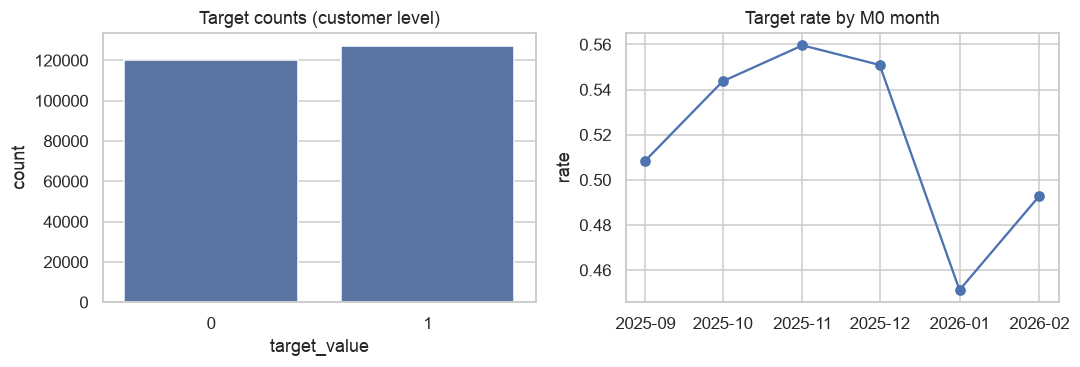

,target_rate,n_customers
month,,
2025-09-01,0.5086,35252
2025-10-01,0.5437,39222
2025-11-01,0.5596,36403
2025-12-01,0.5509,41662
2026-01-01,0.4512,50601
2026-02-01,0.4929,44114


In [7]:
vc = cust[TARGET].value_counts(dropna=False).sort_index()
rate = cust[TARGET].mean()
print(vc.to_string())
print(f"\nPositive rate (missed payments): {rate:.2%}   |   imbalance ratio ~ 1:{(1-rate)/rate:,.1f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
sns.countplot(x=TARGET, data=cust, ax=ax[0])
ax[0].set_title("Target counts (customer level)")
tmp = cust.dropna(subset=[M0]).assign(month=lambda d: d[M0].dt.to_period("M").dt.to_timestamp())
m = tmp.groupby("month")[TARGET].agg(["mean", "count"])
ax[1].plot(m.index, m["mean"], marker="o")
ax[1].set_title("Target rate by M0 month"); ax[1].set_ylabel("rate")
plt.tight_layout(); plt.show()
display(m.rename(columns={"mean": "target_rate", "count": "n_customers"}))

In [8]:
# Validate the label definition: target = 1 if payment_count < due_count
if {"payment_count", "due_count"} <= set(cust.columns):
    derived = (cust["payment_count"] < cust["due_count"]).astype(int)
    mismatch = (derived != cust[TARGET])
    print(f"Label disagrees with (payment_count < due_count) for {mismatch.sum():,} rows ({mismatch.mean():.2%})")
    if mismatch.any():
        display(cust.loc[mismatch, ["due_count", "payment_count", TARGET]].head(10))
    display(pd.crosstab(cust["due_count"], cust["payment_count"], margins=True))

Label disagrees with (payment_count < due_count) for 45,635 rows (18.46%)


,due_count,payment_count,target_value
12,3,5,1
22,3,3,1
23,3,3,1
24,3,3,1
25,3,3,1
30,3,3,1
31,3,3,1
38,3,3,1
41,3,3,1
43,3,3,1


payment_count,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,69,70,71,72,73,74,75,76,77,78,83,84,85,86,91,94,95,107,109,113,121,161,All
due_count,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,198,233,294,189,76,29,23,11,4,3,7,1,3,0,1,4,1,2,1,1,0,2,0,1,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1087
2,418,324,392,387,298,222,117,79,59,45,31,20,20,26,12,11,6,6,6,7,7,6,3,1,2,1,3,2,7,2,0,1,1,0,4,3,0,1,1,1,1,0,0,0,1,0,2,0,2,1,0,1,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,2544
3,54302,17673,23691,39846,49911,22150,19477,6791,3294,1830,1108,713,540,370,306,234,175,158,123,98,95,65,84,55,44,55,38,28,32,20,34,25,16,23,18,14,12,7,12,10,7,8,8,7,6,7,15,5,3,5,5,3,4,1,5,1,2,2,2,2,2,1,1,6,3,1,2,1,3,2,1,2,4,1,1,0,3,0,1,1,1,1,2,1,1,1,1,1,2,1,243623
All,54918,18230,24377,40422,50285,22401,19617,6881,3357,1878,1146,734,563,396,319,249,182,166,130,106,102,73,87,57,46,56,41,30,40,22,34,26,18,23,22,17,12,8,13,11,8,8,8,7,7,7,17,5,5,6,5,4,5,1,5,2,2,2,2,2,2,1,1,6,3,1,2,1,3,2,1,2,4,1,1,1,3,1,1,1,1,1,2,1,2,1,1,1,2,1,247254


## 5. Customer-level (account) variables vs target

Note: `payment_count` and `total_paid` describe the outcome period, so they are shown here for
understanding and label validation only. They must **not** be used as predictors.

In [9]:
def slog(x):
    """Signed log transform, handles zero/negative values."""
    return np.sign(x) * np.log1p(np.abs(x))

c = cust.copy()
if {"payment_count", "due_count"} <= set(c.columns):
    c["payment_ratio"] = c["payment_count"] / c["due_count"].replace(0, np.nan)
if {"total_paid", "m0_total_due_with_arrears"} <= set(c.columns):
    c["paid_to_due_ratio"] = c["total_paid"] / c["m0_total_due_with_arrears"].replace(0, np.nan)
if {"m0_arrearsamount", "m0_total_due_with_arrears"} <= set(c.columns):
    c["arrears_share_of_due"] = c["m0_arrearsamount"] / c["m0_total_due_with_arrears"].replace(0, np.nan)

num_cols = [x for x in CUST_NUM + ["payment_ratio", "paid_to_due_ratio", "arrears_share_of_due"] if x in c.columns]
display(c.groupby(TARGET)[num_cols].describe().T)

target_value                                 0            1
m0_arrearsamount          count   120,105.0000 127,149.0000
                          mean      1,146.0627   1,671.3760
                          std       1,823.2376   2,847.2151
                          min          50.0000      50.0000
                          25%         354.1200     473.4000
                          50%         682.2400     911.7800
                          75%       1,361.7500   1,847.8300
                          max     333,902.2300 197,593.5300
due_count                 count   120,105.0000 127,149.0000
                          mean          2.9706       2.9906
                          std           0.2080       0.1116
                          min           1.0000       1.0000
                          25%           3.0000       3.0000
                          50%           3.0000       3.0000
                          75%           3.0000       3.0000
                          max           3.0000       3.0000
payment_count             count   120,105.0000 127,149.0000
                          mean          4.6851       1.7790
                          std           3.3624       2.1536
                          min           0.0000       0.0000
                          25%           3.0000       0.0000
                          50%           4.0000       1.0000
                          75%           5.0000       3.0000
                          max         161.0000      60.0000
m0_total_due_with_arrears count   120,105.0000 127,149.0000
                          mean      4,076.5653   4,690.0132
                          std       5,707.0807   7,169.7245
                          min        -596.6200     -29.7100
                          25%       1,383.1900   1,384.4300
                          50%       2,556.8800   2,532.3200
                          75%       5,057.8100   5,331.7200
                          max   1,138,196.4000 222,572.3400
total_paid                count   120,105.0000 127,149.0000
                          mean      6,871.5866     838.7331
                          std      18,530.8805   2,120.0462
                          min     -13,311.2200 -25,000.0000
                          25%       1,529.4900       0.0000
                          50%       3,052.8800       0.0000
                          75%       6,723.0600     862.0900
                          max   1,744,901.2200 145,700.0000
payment_ratio             count   120,105.0000 127,149.0000
                          mean          1.5891       0.5945
                          std           1.2093       0.7189
                          min           0.0000       0.0000
                          25%           1.0000       0.0000
                          50%           1.3333       0.3333
                          75%           1.6667       1.0000
                          max          76.0000      20.0000
paid_to_due_ratio         count   120,105.0000 127,149.0000
                          mean          1.9490       0.2142
                          std           7.6643       0.4418
                          min         -34.8927      -3.2509
                          25%           0.9613       0.0000
                          50%           1.0000       0.0000
                          75%           1.2371       0.4146
                          max       1,817.2458      80.1607
arrears_share_of_due      count   120,105.0000 127,149.0000
                          mean          0.2858       0.3755
                          std           0.1092       0.1617
                          min          -0.3569     -14.6221
                          25%           0.2358       0.2589
                          50%           0.2693       0.3477
                          75%           0.3244       0.4709
                          max           1.3710       1.1735

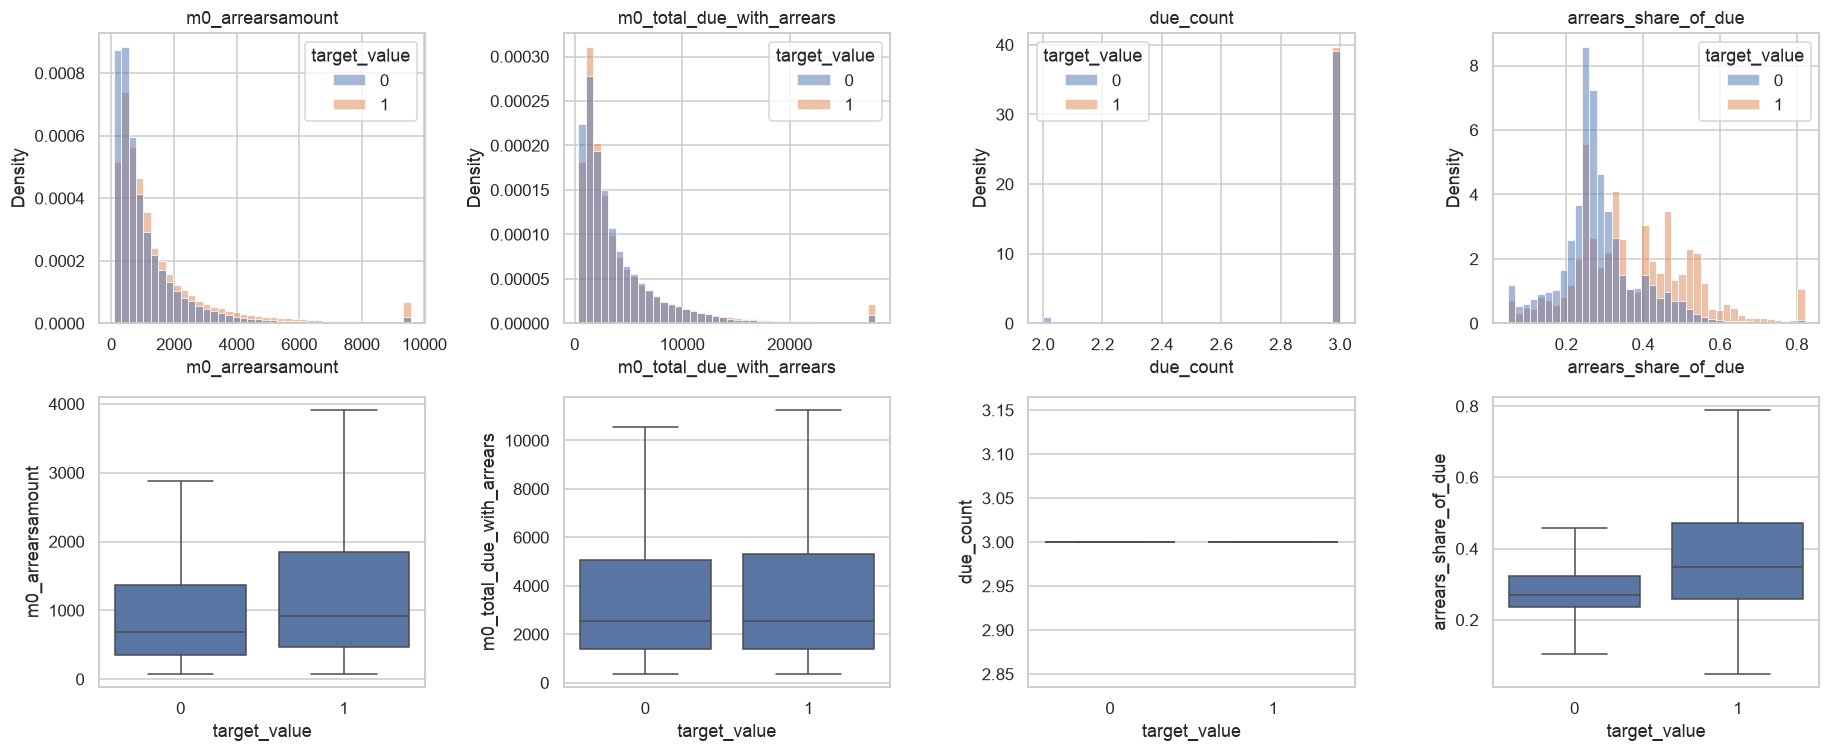

In [10]:
plot_cols = [x for x in ["m0_arrearsamount", "m0_total_due_with_arrears", "due_count", "arrears_share_of_due"] if x in c.columns]
fig, axes = plt.subplots(2, len(plot_cols), figsize=(4.2 * len(plot_cols), 7))
axes = np.atleast_2d(axes)
for i, col in enumerate(plot_cols):
    s = c[col].dropna()
    lo, hi = s.quantile([0.01, 0.99])
    d = c[[col, TARGET]].dropna()
    d[col] = d[col].clip(lo, hi)
    sns.histplot(data=d, x=col, hue=TARGET, stat="density", common_norm=False, bins=40, ax=axes[0, i])
    axes[0, i].set_title(col)
    sns.boxplot(data=d, x=TARGET, y=col, showfliers=False, ax=axes[1, i])
plt.tight_layout(); plt.show()

In [11]:
# Univariate separation of account-level (non-leaky) variables
rows = []
for col in [x for x in num_cols if x not in LEAKY and x not in ["payment_ratio", "paid_to_due_ratio"]]:
    a = c.loc[c[TARGET] == 1, col].dropna(); b = c.loc[c[TARGET] == 0, col].dropna()
    if len(a) > 20 and len(b) > 20:
        u, p = stats.mannwhitneyu(a, b)
        rows.append({"feature": col, "median_target1": a.median(), "median_target0": b.median(),
                     "AUC": u / (len(a) * len(b)), "p_value": p})
display(pd.DataFrame(rows).set_index("feature"))

,median_target1,median_target0,AUC,p_value
feature,,,,
m0_arrearsamount,911.7800,682.2400,0.5891,0.0000
due_count,3.0000,3.0000,0.5071,0.0000
m0_total_due_with_arrears,"2,532.3200","2,556.8800",0.5127,0.0000
arrears_share_of_due,0.3477,0.2693,0.6825,0.0000


,count,n_pos,rate,ci_lo,ci_hi,lift
collectionsmethodname,,,,,,
"Early Debit Order, linked to clients paydate",174756,100964,0.5777,0.5754,0.5801,1.1235
Debit Order,68717,24879,0.3621,0.3585,0.3657,0.7040
"Credit push, client pays via EFT",3781,1306,0.3454,0.3304,0.3607,0.6717


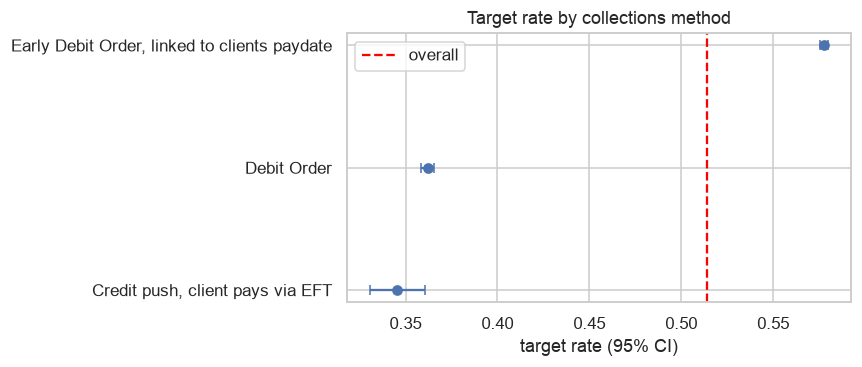

In [12]:
def rate_table(d, col, target=TARGET, min_n=30, top=None):
    """Target rate by category with Wilson 95% CI and lift vs overall rate."""
    g = d.groupby(col, observed=True)[target].agg(["count", "sum"]).rename(columns={"sum": "n_pos"})
    g["rate"] = g["n_pos"] / g["count"]
    lo, hi = proportion_confint(g["n_pos"], g["count"], method="wilson")
    g["ci_lo"], g["ci_hi"] = lo, hi
    g["lift"] = g["rate"] / d[target].mean()
    g = g[g["count"] >= min_n].sort_values("count", ascending=False)
    return g.head(top) if top else g

if METHOD in cust.columns:
    rt = rate_table(cust, METHOD)
    display(rt)
    fig, ax = plt.subplots(figsize=(8, 0.5 * len(rt) + 2))
    rt_s = rt.sort_values("rate")
    ax.errorbar(rt_s["rate"], range(len(rt_s)),
                xerr=[rt_s["rate"] - rt_s["ci_lo"], rt_s["ci_hi"] - rt_s["rate"]], fmt="o", capsize=3)
    ax.set_yticks(range(len(rt_s))); ax.set_yticklabels(rt_s.index)
    ax.axvline(cust[TARGET].mean(), color="red", ls="--", label="overall")
    ax.set_xlabel("target rate (95% CI)"); ax.set_title("Target rate by collections method"); ax.legend()
    plt.tight_layout(); plt.show()

## 6. Transaction-level overview

Transactions: 106,310,906 across 120,424 customers
Date range  : 2025-05-01 -> 2026-03-07


,count,mean,std,min,5%,25%,50%,75%,95%,max
transactions per customer,"247,254.0000",429.9664,412.0925,1.0000,50.0000,139.0000,304.0000,589.0000,"1,228.0000","9,059.0000"



Inflows (amount>0): 23.9% of rows | outflows (amount<0): 76.1% | zero: 0.0%
Balance negative at transaction time: 7.8%


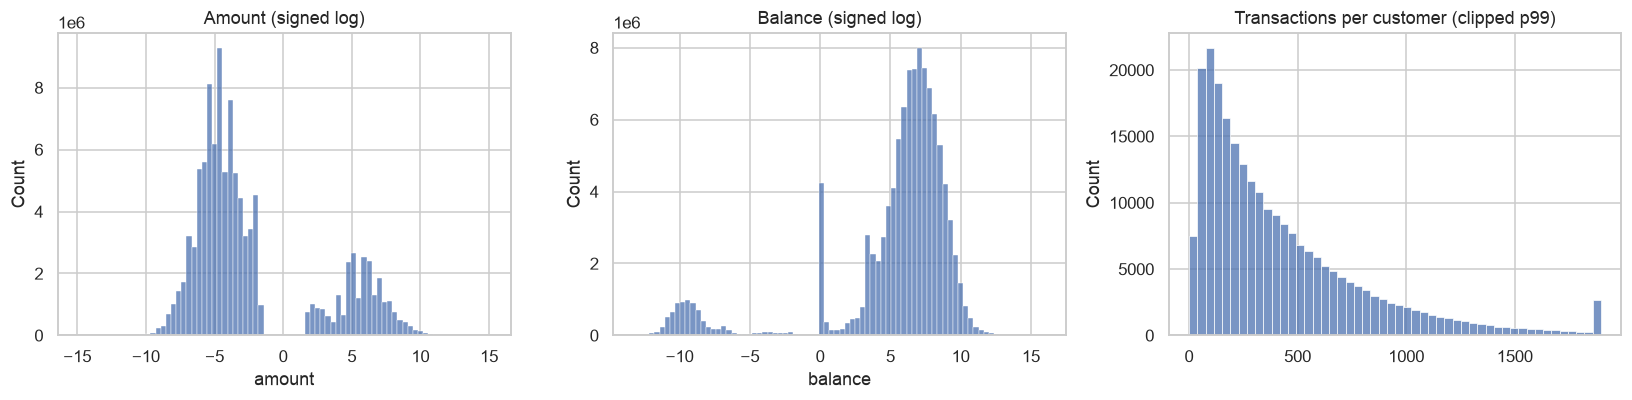

In [13]:
print(f"Transactions: {len(txn):,} across {txn[ID].nunique():,} customers")
print(f"Date range  : {txn[TXN_DATE].min().date()} -> {txn[TXN_DATE].max().date()}")

tpc = txn.groupby(KEY, dropna=False).size()
display(tpc.describe(percentiles=[.05, .25, .5, .75, .95]).to_frame("transactions per customer").T)

print(f"\nInflows (amount>0): {(txn[AMT] > 0).mean():.1%} of rows | outflows (amount<0): {(txn[AMT] < 0).mean():.1%} | zero: {(txn[AMT] == 0).mean():.1%}")
print(f"Balance negative at transaction time: {(txn[BAL] < 0).mean():.1%}")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
sns.histplot(slog(txn[AMT].dropna()), bins=80, ax=ax[0]); ax[0].set_title("Amount (signed log)")
sns.histplot(slog(txn[BAL].dropna()), bins=80, ax=ax[1]); ax[1].set_title("Balance (signed log)")
sns.histplot(tpc.clip(upper=tpc.quantile(.99)), bins=50, ax=ax[2]); ax[2].set_title("Transactions per customer (clipped p99)")
plt.tight_layout(); plt.show()


=== trantypedesc: 256 levels (top 20 shown) ===


,n,net_amount,mean_amount,pct_inflow,share_%
trantypedesc,,,,,
Card Purchase,28185265,"-6,898,779,121.5600",-244.7655,0.0000,26.5121
Transfer,9783050,"-8,273,423,036.8300",-845.6895,0.0787,9.2023
Transfer Received,8361001,"8,880,728,366.6400","1,062.1609",1.0000,7.8647
Prepaid Purchase,6735673,"-316,183,742.5000",-46.9417,0.0000,6.3358
Payment Received,6634121,"17,345,401,881.3000","2,614.5742",1.0000,6.2403
Immediate Payment,5760536,"-5,182,882,645.8500",-899.7223,0.0000,5.4186
Voucher Purchase,3283278,"-359,653,370.2000",-109.5409,0.0000,3.0884
Immediate Capitec Pay Payment,2733398,"-822,173,180.5000",-300.7879,0.0000,2.5711
Cash Withdrawal,2711075,"-2,185,817,500.4400",-806.2549,0.0000,2.5501


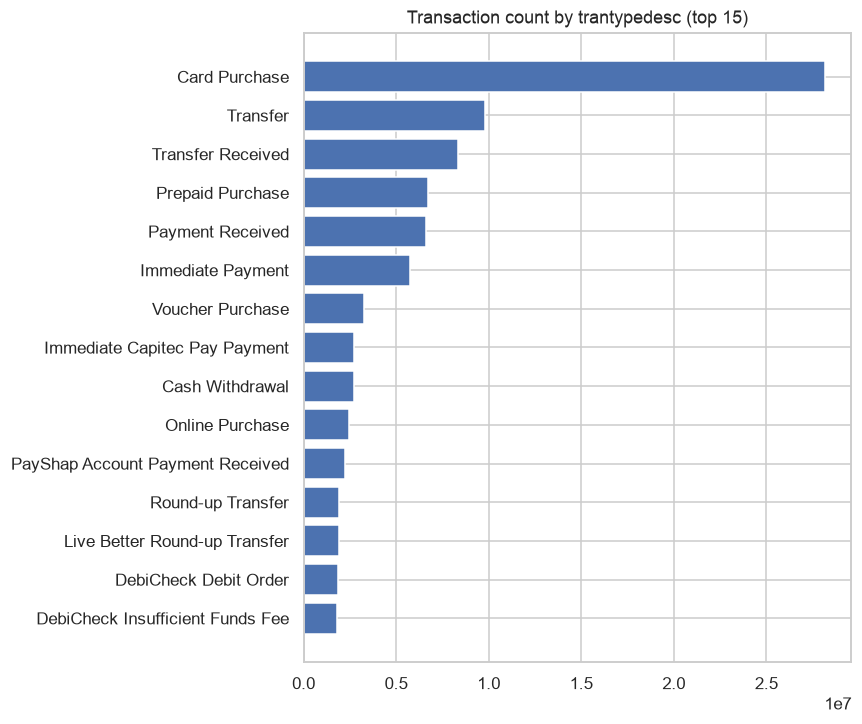


=== spendgroup: 38 levels (top 20 shown) ===


,n,net_amount,mean_amount,pct_inflow,share_%
spendgroup,,,,,
InternalTransfer,20327523,"530,671,035.5700",26.1060,0.4533,19.1208
CardAuthorisationTransaction,16545946,"-4,136,154,500.6300",-249.9799,0.0001,15.5637
CardTransaction,16161153,"-4,068,461,244.7700",-251.7433,0.0019,15.2018
MoneyIn,9196519,"19,593,354,286.1900","2,130.5185",0.9986,8.6506
Prepaid,6959785,"-308,443,333.5000",-44.3179,0.0271,6.5466
PaymentInternal,6216775,"-5,572,946,315.5300",-896.4369,0.0012,5.8477
Fee,4695579,"-59,160,601.2400",-12.5992,0.0133,4.4168
Vouchers,3290794,"-358,831,195.1200",-109.0409,0.0023,3.0954
CapitecPay,2878268,"-903,777,103.2300",-314.0003,0.0000,2.7074


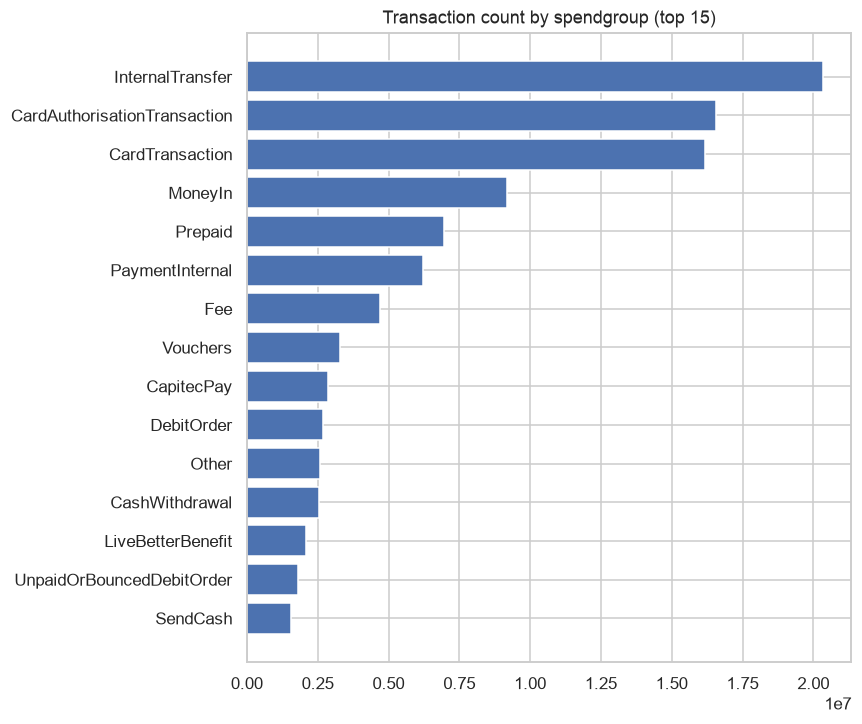


=== categoryname: 103 levels (top 20 shown) ===


,n,net_amount,mean_amount,pct_inflow,share_%
categoryname,,,,,
Transfer,20391338,"511,206,877.7600",25.0698,0.4535,19.1809
Groceries,13398899,"-2,895,714,306.1600",-216.1158,0.0001,12.6035
Other Income,7672036,"10,764,993,150.8300","1,403.1469",0.9996,7.2166
Cellphone,7568039,"-423,038,734.9100",-55.8981,0.0162,7.1188
Betting/Lottery,6945005,"-889,890,892.1500",-128.1339,0.0635,6.5327
Digital Payments,6924913,"-6,945,996,349.9900","-1,003.0446",0.0035,6.5138
Fees,4695579,"-59,160,601.2400",-12.5992,0.0133,4.4168
Cash Withdrawal,4298621,"-2,866,819,990.8600",-666.9162,0.0252,4.0434
Uncategorised,3279708,"188,718,276.2800",57.5412,0.4819,3.0850


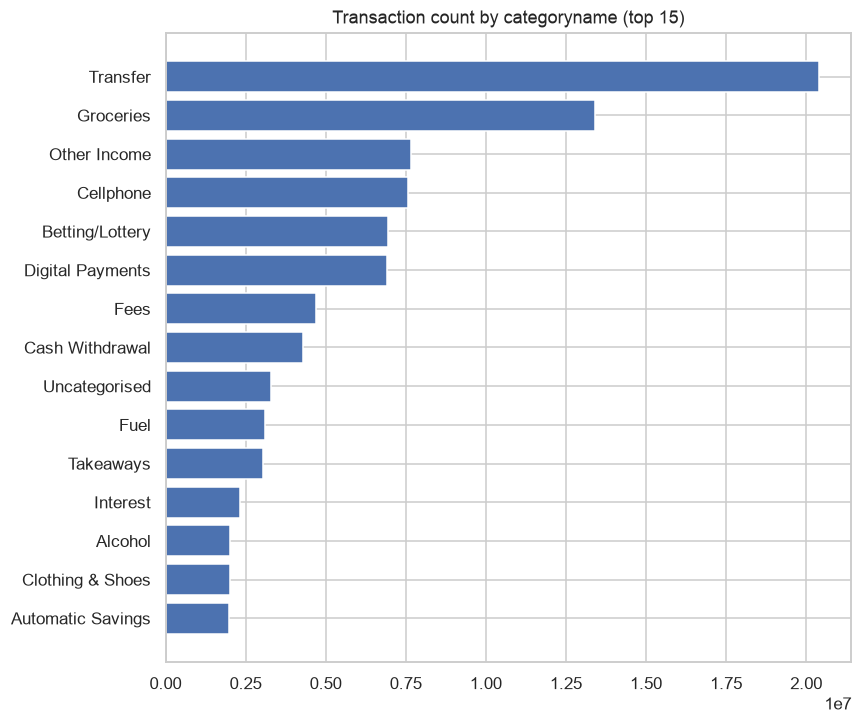

In [14]:
# Categorical structure of transactions
for col in [TXN_TYPE, SPEND, CAT]:
    if col not in txn.columns:
        continue
    g = (txn.groupby(col, observed=True)
            .agg(n=(AMT, "size"), net_amount=(AMT, "sum"), mean_amount=(AMT, "mean"),
                 pct_inflow=(AMT, lambda s: (s > 0).mean()))
            .sort_values("n", ascending=False))
    g["share_%"] = g["n"] / g["n"].sum() * 100
    print(f"\n=== {col}: {len(g)} levels (top 20 shown) ===")
    display(g.head(20))
    top = g.head(15).sort_values("n")
    fig, ax = plt.subplots(figsize=(8, 0.35 * len(top) + 1.5))
    ax.barh(top.index.astype(str), top["n"]); ax.set_title(f"Transaction count by {col} (top 15)")
    plt.tight_layout(); plt.show()

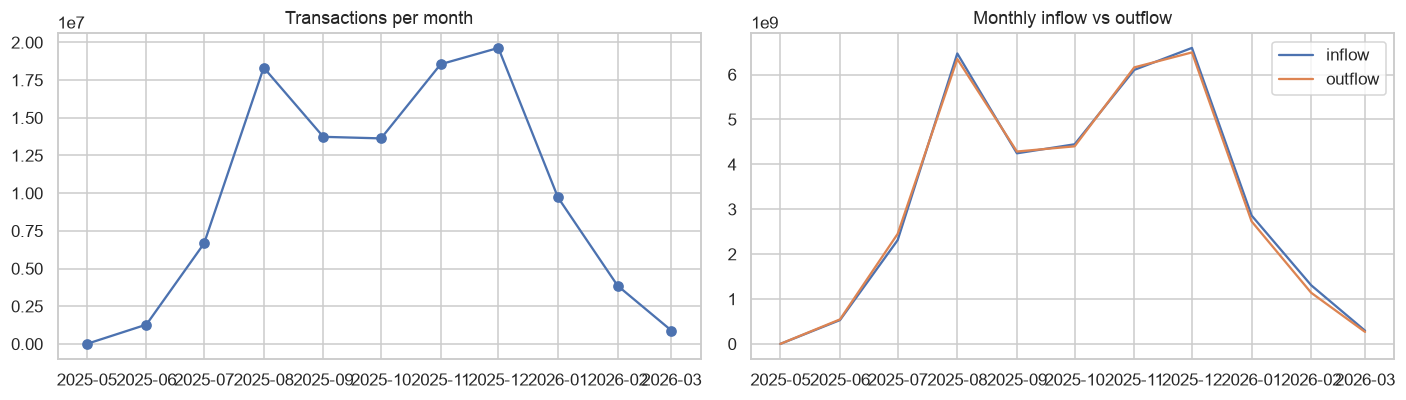

In [15]:
# Monthly volume and net flow
mt = txn.assign(month=txn[TXN_DATE].dt.to_period("M").dt.to_timestamp())
mm = mt.groupby("month").agg(n=(AMT, "size"),
                             inflow=(AMT, lambda s: s[s > 0].sum()),
                             outflow=(AMT, lambda s: -s[s < 0].sum()))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].plot(mm.index, mm["n"], marker="o"); ax[0].set_title("Transactions per month")
ax[1].plot(mm.index, mm["inflow"], label="inflow"); ax[1].plot(mm.index, mm["outflow"], label="outflow")
ax[1].legend(); ax[1].set_title("Monthly inflow vs outflow")
plt.tight_layout(); plt.show()

## 7. Time windows and leakage checks

Features must use only information available **at or before M0**, because the target is measured in the
3 months after M0. We check how much transaction history sits before vs after M0.

Transactions dated AFTER M0 (must be excluded from features): 3,990,158 (3.75%)
Transactions within the 90-day window before M0: 83.03%


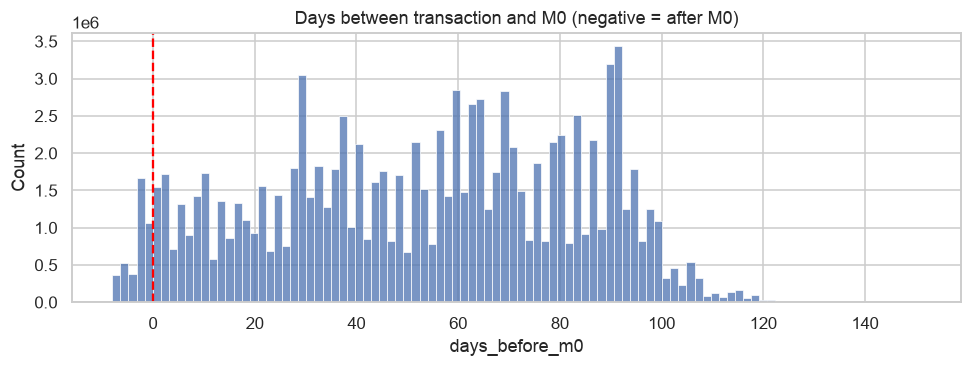

,count,mean,std,min,5%,25%,50%,75%,95%,max
max days of history before M0,"247,254.0000",98.0430,7.5243,28.0000,90.0000,93.0000,96.0000,100.0000,115.0000,151.0000


Customers in cust table with NO pre-M0 transactions: 0


,count,mean,std,min,25%,50%,75%,max
payment_date - M0 (days),"247,503.0000","-24,096.4863",50.7473,"-24,187.0000","-24,127.0000","-24,111.0000","-24,061.0000","-23,990.0000"


In [16]:
txn["days_before_m0"] = (txn[M0] - txn[TXN_DATE]).dt.days
after = (txn["days_before_m0"] < 0)
print(f"Transactions dated AFTER M0 (must be excluded from features): {after.sum():,} ({after.mean():.2%})")
print(f"Transactions within the {WINDOW_DAYS}-day window before M0: "
      f"{((txn['days_before_m0'] >= 0) & (txn['days_before_m0'] < WINDOW_DAYS)).mean():.2%}")

fig, ax = plt.subplots(figsize=(9, 3.5))
sns.histplot(txn["days_before_m0"].clip(-120, 400), bins=100, ax=ax)
ax.axvline(0, color="red", ls="--"); ax.set_title("Days between transaction and M0 (negative = after M0)")
plt.tight_layout(); plt.show()

# History coverage per customer (pre-M0)
pre = txn[txn["days_before_m0"] >= 0]
cov = pre.groupby(KEY, dropna=False)["days_before_m0"].max()
display(cov.describe(percentiles=[.05, .25, .5, .75, .95]).to_frame("max days of history before M0").T)
print(f"Customers in cust table with NO pre-M0 transactions: {len(cust) - len(cov):,}")

# Payment dates relative to M0
pay2 = pay.dropna(subset=[PAY_DATE, M0]).copy()
pay2["days_after_m0"] = (pay2[PAY_DATE] - pay2[M0]).dt.days
display(pay2["days_after_m0"].describe().to_frame("payment_date - M0 (days)").T)

In [17]:
# Is the transaction extract anchored on payment_date rather than on M0?
last_txn = txn.groupby(ID)[TXN_DATE].max().rename("last_txn")
chk = pay.drop_duplicates(subset=ID).set_index(ID)[[M0, PAY_DATE]].join(last_txn)
gap_pay = (chk[PAY_DATE] - chk["last_txn"]).dt.days
gap_m0 = (chk[M0] - chk["last_txn"]).dt.days
display(pd.concat([gap_pay.describe().rename("payment_date - last txn (days)"),
                   gap_m0.describe().rename("M0 - last txn (days)")], axis=1).T)
print(f"Customers whose last transaction is within 1 day of payment_date: {(gap_pay.abs() <= 1).mean():.1%}")
print("If this share is high, the extract ends at payment_date, not M0: 'days since' features measured from M0 then mostly encode the payment_date offset.")
del last_txn, chk, gap_pay, gap_m0

,count,mean,std,min,25%,50%,75%,max
payment_date - last txn (days),"120,424.0000","-24,120.2888",50.6786,"-24,198.0000","-24,167.0000","-24,128.0000","-24,079.0000","-23,960.0000"
M0 - last txn (days),"120,424.0000",-41.0186,47.4690,-159.0000,-66.0000,-31.0000,-3.0000,66.0000


Customers whose last transaction is within 1 day of payment_date: 0.0%
If this share is high, the extract ends at payment_date, not M0: 'days since' features measured from M0 then mostly encode the payment_date offset.


## 8. Feature construction: static vs time-aware

**Memory-safe design (52M-row scale).** Features are built in batches of customers from a slim, integer-keyed copy of the transactions
(customer code, days-before-M0 as int16, amount, balance, category). The large `df` / `txn` frames are freed first, so peak memory is roughly
the slim table plus one batch instead of several full-size copies.

Feature groups (disjoint), all computed strictly from transactions on or before M0 and within the last 90 days
(the extract only holds about 98 days of history per customer):

| Group | Type | Examples |
|---|---|---|
| `static` | Static account attributes | arrears amount, total due, due count, collections method |
| `snapshot` | Point-in-time | balance at M0 (last observed balance) |
| `flat` | Time-agnostic aggregates | 90-day totals, balance mean/min, share of spend by category |
| `recent` | Time-aware | the same quantities over only the last 14 and 30 days |
| `trend` | Time-aware | last 14 / 30 / 45 days vs the rest of the 90 days, per-30-day rates, for inflow, outflow, activity, balance |
| `weekly` | Time-aware | slope and volatility of weekly balance / inflow / outflow / net flow, weeks of negative net flow |
| `recency` | Time-aware | days since last inflow, longest gap between inflows, overdraft crossings |
| `cat_shift` | Time-aware | recent vs prior change in spend-category mix |

`flat` contains the *same raw information* as many time-aware features but collapses it into one window,
so `E vs C` below isolates what temporal structure adds.

In [18]:
import gc, time

# ---------------- feature settings ----------------
MAX_W = 90                # look-back used for every feature (extract holds ~98 days before M0)
FLAT_WINDOW = 90          # window for time-agnostic aggregates
N_WEEKS = 12              # weekly panel length; needs 7 * N_WEEKS <= MAX_W
BATCH_CUSTOMERS = 10_000  # customers per batch; lower this if memory is still tight
MIX_COL = CAT             # column for spend-mix features (categoryname is more meaningful than spendgroup)
MIX_EXCLUDE = ["Transfer"]  # mostly internal movements; excluded from the spend mix only
assert 7 * N_WEEKS <= MAX_W
# Some customers have several M0 months, so the unit of analysis is (customer, M0), not customer.
assert not cust.duplicated(subset=KEY).any(), "cust must have one row per (customer, M0)."
HAS_MIX = MIX_COL in txn.columns

# Integer code per (customer, M0) key: much cheaper to group on than (string id, date).
# A customer with two M0 months gets two codes, so each observation keeps its own look-back window.
_g = txn.groupby(KEY, sort=False, dropna=False)
txn["cid"] = _g.ngroup().astype("int32")
uniques = _g.size().index                     # (customer, M0) keys, in code order
del _g
_keys = uniques.to_frame(index=False)
_keys["cid"] = np.arange(len(_keys), dtype="int32")
cust = cust.drop(columns="cid", errors="ignore").merge(_keys, on=KEY, how="left")
cust["cid"] = cust["cid"].fillna(-1).astype("int32")
del _keys
print(f"(customer, M0) keys with transactions: {len(uniques):,} | keys in cust table without any: {(cust['cid'] < 0).sum():,}")

# Slim transaction table: only what the features need, only the look-back window, sorted by customer
keep = ["cid", "days_before_m0", AMT, BAL] + ([MIX_COL] if HAS_MIX else [])
sel = ((txn["days_before_m0"] >= 0) & (txn["days_before_m0"] < MAX_W)).to_numpy()
txn_s = txn.loc[sel, keep].rename(columns={"days_before_m0": "dbm"})
txn_s["dbm"] = txn_s["dbm"].astype("int16")
del sel

# Free the big frames (EDA sections above are finished with them)
globals().pop("df", None)
del txn
gc.collect()
txn_s = txn_s.sort_values("cid", kind="stable", ignore_index=True)
cid_arr = txn_s["cid"].to_numpy()
print(f"Slim table: {len(txn_s):,} rows, {txn_s.memory_usage(deep=True).sum() / 1e9:.2f} GB")

if HAS_MIX:
    neg = txn_s[txn_s[AMT] < 0]
    _out = (-neg[AMT]).groupby(neg[MIX_COL], observed=True).sum()
    _out = _out[~_out.index.isin(MIX_EXCLUDE)].sort_values(ascending=False)
    TOP_GROUPS = [str(g) for g in _out.head(12).index]
    TOP6 = TOP_GROUPS[:6]
    del neg, _out
    print("Top spend categories:", TOP_GROUPS)

(customer, M0) keys with transactions: 247,254 | keys in cust table without any: 0
Slim table: 88,268,145 rows, 2.03 GB
Top spend categories: ['Digital Payments', 'Cash Withdrawal', 'Groceries', 'Uncategorised', 'Other Loans & Accounts', 'Betting/Lottery', 'Clothing & Shoes', 'Fuel', 'Loan Payments', 'Children & Dependants', 'Cellphone', 'Takeaways']


In [19]:
def slog_np(A):
    return np.sign(A) * np.log1p(np.abs(A))

def clean(name):
    return str(name).lower().replace(" ", "_").replace("/", "_").replace("&", "and")

CID = "cid"
ZERO_COLS = ["n_txn", "inflow", "outflow"]

def prep(h):
    """Within-customer chronological order (oldest first) and helper columns, in float64 for accurate sums."""
    h = h.sort_values([CID, "dbm"], ascending=[True, False]).astype({AMT: "float64", BAL: "float64"})
    h = h.assign(inflow=h[AMT].clip(lower=0), outflow=(-h[AMT]).clip(lower=0),
                 is_in=(h[AMT] > 0).astype("int8"), is_out=(h[AMT] < 0).astype("int8"),
                 neg_bal=(h[BAL] < 0).astype("int8"))
    if HAS_MIX:
        h[MIX_COL] = h[MIX_COL].astype(str)
    return h

def win_agg(h, lo, hi, idx):
    """Aggregates over days-before-M0 in [lo, hi), aligned to every customer in idx."""
    d = h[(h["dbm"] >= lo) & (h["dbm"] < hi)]
    out = (d.groupby(CID)
             .agg(n_txn=(AMT, "size"), inflow=("inflow", "sum"), outflow=("outflow", "sum"),
                  bal_mean=(BAL, "mean"), bal_min=(BAL, "min"), pct_neg=("neg_bal", "mean"))
             .reindex(idx))
    out[ZERO_COLS] = out[ZERO_COLS].fillna(0)
    out["net"] = out["inflow"] - out["outflow"]
    return out

def spend_share(h, lo, hi, groups, idx):
    d = h[(h["dbm"] >= lo) & (h["dbm"] < hi) & (h[AMT] < 0) & (~h[MIX_COL].isin(MIX_EXCLUDE))]
    if len(d) == 0:
        return pd.DataFrame(np.nan, index=idx, columns=groups)
    sp_all = d.groupby([CID, MIX_COL])["outflow"].sum().unstack(fill_value=0)
    total = sp_all.sum(axis=1).replace(0, np.nan)
    sp = sp_all.reindex(columns=groups, fill_value=0)
    return sp.div(total, axis=0).reindex(idx)

def row_slope(M):
    """OLS slope per row of a (customers x weeks) matrix, NaN-aware. x increases toward M0."""
    A = M.to_numpy(dtype=float)
    x = np.arange(A.shape[1], dtype=float)
    mask = ~np.isnan(A)
    n = mask.sum(1)
    Af = np.where(mask, A, 0.0)
    with np.errstate(invalid="ignore", divide="ignore"):
        xm = (mask * x).sum(1) / n
        ym = Af.sum(1) / n
        dx = (x[None, :] - xm[:, None]) * mask
        num = (dx * (Af - ym[:, None])).sum(1)
        den = (dx ** 2).sum(1)
        out = np.where((n >= 3) & (den > 0), num / den, np.nan)
    return pd.Series(out, index=M.index)

def build_snapshot(h, idx):
    s = h.groupby(CID)[BAL].last().reindex(idx).rename("bal_at_m0").to_frame()
    s["no_history"] = s["bal_at_m0"].isna().astype("int8")
    return s

def build_flat(h, idx):
    """Time-agnostic aggregates over one window."""
    W = FLAT_WINDOW
    f = win_agg(h, 0, W, idx).add_suffix(f"_{W}d")
    d = h[h["dbm"] < W]
    ex = (d.groupby(CID)
            .agg(n_inflow=("is_in", "sum"), n_outflow=("is_out", "sum"),
                 max_inflow=("inflow", "max"), max_outflow=("outflow", "max"), bal_std=(BAL, "std"))
            .reindex(idx).add_suffix(f"_{W}d"))
    ex[[f"n_inflow_{W}d", f"n_outflow_{W}d"]] = ex[[f"n_inflow_{W}d", f"n_outflow_{W}d"]].fillna(0)
    f = f.join(ex)
    f[f"outflow_to_inflow_{W}d"] = f[f"outflow_{W}d"] / f[f"inflow_{W}d"].replace(0, np.nan)
    f[f"avg_outflow_size_{W}d"] = f[f"outflow_{W}d"] / f[f"n_outflow_{W}d"].replace(0, np.nan)
    f[f"avg_inflow_size_{W}d"] = f[f"inflow_{W}d"] / f[f"n_inflow_{W}d"].replace(0, np.nan)
    inc = d[d[AMT] > 0].groupby(CID)[AMT].agg(["mean", "std"]).reindex(idx)
    f[f"inflow_cv_{W}d"] = inc["std"] / inc["mean"]
    if HAS_MIX:
        sh = spend_share(h, 0, W, TOP_GROUPS, idx)
        sh.columns = [f"share_{clean(c)}_{W}d" for c in sh.columns]
        f = f.join(sh)
    return f

def build_time(h, idx):
    """Time-aware features: recent levels, trends, weekly dynamics, recency, mix shift."""
    r14, p76 = win_agg(h, 0, 14, idx), win_agg(h, 14, MAX_W, idx)
    r30, p60 = win_agg(h, 0, 30, idx), win_agg(h, 30, MAX_W, idx)
    r45, p45 = win_agg(h, 0, 45, idx), win_agg(h, 45, MAX_W, idx)
    recent = pd.concat([r14.add_suffix("_14d"), r30.add_suffix("_30d")], axis=1)

    # trends: recent window vs the rest of the look-back, both expressed as per-30-day rates
    tr = pd.DataFrame(index=idx)
    for tag, r, p, dr, dp in [("14", r14, p76, 14, MAX_W - 14), ("30", r30, p60, 30, MAX_W - 30), ("45", r45, p45, 45, MAX_W - 45)]:
        for nm in ["inflow", "outflow", "n_txn"]:
            tr[f"{nm}_trend{tag}"] = slog(r[nm] * 30.0 / dr) - slog(p[nm] * 30.0 / dp)
        tr[f"bal_mean_delta{tag}"] = r["bal_mean"] - p["bal_mean"]
        tr[f"pct_neg_delta{tag}"] = r["pct_neg"] - p["pct_neg"]

    # weekly panel: slope and volatility
    d = h[h["dbm"] < 7 * N_WEEKS]
    d = d.assign(wk=((N_WEEKS - 1) - (d["dbm"] // 7)).astype("int16"))   # 0 = oldest week, N_WEEKS-1 = week before M0
    g = d.groupby([CID, "wk"])
    cols_ = range(N_WEEKS)
    inflow = g["inflow"].sum().unstack("wk").reindex(index=idx, columns=cols_).fillna(0)
    outflow = g["outflow"].sum().unstack("wk").reindex(index=idx, columns=cols_).fillna(0)
    bal = g[BAL].last().unstack("wk").reindex(index=idx, columns=cols_).ffill(axis=1)
    net = inflow - outflow
    wk = pd.DataFrame(index=idx)
    wk["bal_slope"] = row_slope(bal)
    wk["inflow_slope"] = row_slope(inflow)
    wk["outflow_slope"] = row_slope(outflow)
    wk["net_slope"] = row_slope(net)
    wk["net_std"] = net.std(axis=1)
    wk["bal_wk_std"] = bal.std(axis=1)
    wk["weeks_net_neg"] = (net < 0).sum(axis=1)
    wk["weeks_bal_neg"] = (bal < 0).sum(axis=1)
    wk["bal_drawdown"] = bal.iloc[:, -1] - bal.max(axis=1)
    wk["weeks_active"] = ((inflow + outflow) > 0).sum(axis=1)

    # recency and gaps (measured from M0; see the anchor check in section 7)
    gk = h.groupby(CID)
    rec = pd.DataFrame({"days_since_last_txn": gk["dbm"].min()})
    pos = h[h[AMT] > 0]
    rec["days_since_last_inflow"] = pos.groupby(CID)["dbm"].min()
    gap = pos.assign(gap=pos.groupby(CID)["dbm"].diff().abs())
    gs = gap.groupby(CID)["gap"].agg(["max", "std"])
    rec["longest_inflow_gap"] = gs["max"]
    rec["inflow_gap_std"] = gs["std"]
    rec["days_since_nonneg_bal"] = h[h[BAL] >= 0].groupby(CID)["dbm"].min()
    prev = gk[BAL].shift(1)
    cross = ((prev >= 0) & (h[BAL] < 0)).astype("int8")
    rec["neg_crossings"] = h.assign(cross=cross).groupby(CID)["cross"].sum()
    rec = rec.reindex(idx)
    for c_ in ["days_since_last_txn", "days_since_last_inflow", "days_since_nonneg_bal", "longest_inflow_gap"]:
        rec[c_] = rec[c_].fillna(MAX_W)
    rec["neg_crossings"] = rec["neg_crossings"].fillna(0)

    parts = [recent, tr, wk, rec]
    groups = {"recent": list(recent.columns), "trend": list(tr.columns),
              "weekly": list(wk.columns), "recency": list(rec.columns)}
    if HAS_MIX:
        cs = spend_share(h, 0, 30, TOP6, idx).fillna(0) - spend_share(h, 30, MAX_W, TOP6, idx).fillna(0)
        cs.columns = [f"shift_{clean(c)}" for c in cs.columns]
        parts.append(cs)
        groups["cat_shift"] = list(cs.columns)
    else:
        groups["cat_shift"] = []
    panels = {"balance": bal, "net_flow": net, "outflow": outflow}
    return pd.concat(parts, axis=1), groups, panels

# ---------------- batch driver ----------------
cust_cids = np.sort(cust.loc[cust["cid"] >= 0, "cid"].to_numpy())
BOUNDS = np.arange(0, len(uniques) + BATCH_CUSTOMERS, BATCH_CUSTOMERS)

def shuffle_timing(h, seed):
    """Placebo: randomly reassign the days-before-M0 of each customer's transactions within that customer."""
    h = h.sort_values([CID, "dbm"]).reset_index(drop=True)
    grp = pd.factorize(h[CID])[0]
    r = np.random.default_rng(seed).random(len(h))
    order = np.lexsort((r, grp))                 # random order inside each customer block
    h["dbm"] = h["dbm"].to_numpy()[order]
    return h

def run_batches(parts=("snap", "flat", "time"), shuffle_seed=None, verbose=True):
    out = {"snap": [], "flat": [], "time": []}
    panels, groups, t0, dropped = [], None, time.time(), 0
    nb = len(BOUNDS) - 1
    for b in range(nb):
        lo, hi = BOUNDS[b], BOUNDS[b + 1]
        idx_b = pd.Index(cust_cids[(cust_cids >= lo) & (cust_cids < hi)], name=CID)
        if len(idx_b) == 0:
            continue
        a, z = np.searchsorted(cid_arr, [lo, hi])
        h = txn_s.iloc[a:z].copy()
        if DEDUPE_TXNS:
            n0 = len(h); h = h.drop_duplicates(); dropped += n0 - len(h)
        if shuffle_seed is not None:
            h = shuffle_timing(h, shuffle_seed + b)
        h = prep(h)
        if "snap" in parts: out["snap"].append(build_snapshot(h, idx_b))
        if "flat" in parts: out["flat"].append(build_flat(h, idx_b))
        if "time" in parts:
            t_, groups, p_ = build_time(h, idx_b)
            out["time"].append(t_); panels.append(p_)
        if verbose:
            print(f"batch {b + 1}/{nb}: {len(idx_b):,} customers, {z - a:,} rows, {time.time() - t0:,.0f}s elapsed")
        del h
    res = {k: (pd.concat(v) if v else None) for k, v in out.items()}
    res["groups"] = groups
    res["panels"] = ({k: pd.concat([p[k] for p in panels]) for k in panels[0]} if panels else {})
    if DEDUPE_TXNS and verbose:
        print(f"Duplicate transaction rows dropped: {dropped:,}")
    return res

def to_base(df_):
    """Re-index a customer-code-indexed frame to the (customer, M0) index of `base`."""
    out = df_.reindex(cust["cid"].to_numpy())
    out.index = base.index
    return out

In [20]:
base = cust.set_index(KEY)
y = base[TARGET].astype(int)

# ---- static attributes (known at M0, not derived from transactions)
acct_cols = [c_ for c_ in ["m0_arrearsamount", "m0_total_due_with_arrears", "due_count"] if c_ in base.columns]
static_df = base[acct_cols].copy()
if {"m0_arrearsamount", "m0_total_due_with_arrears"} <= set(base.columns):
    static_df["arrears_share_of_due"] = base["m0_arrearsamount"] / base["m0_total_due_with_arrears"].replace(0, np.nan)
if METHOD in base.columns:
    static_df = static_df.join(pd.get_dummies(base[METHOD].astype(str), prefix="method", dtype=float))

# ---- everything transaction-based, built batch by batch
RES = run_batches()
snap = to_base(RES["snap"]); snap["no_history"] = snap["no_history"].fillna(1)
flat_df = to_base(RES["flat"])
time_df = to_base(RES["time"])
PANELS = {k: to_base(v) for k, v in RES["panels"].items()}
TG = RES["groups"]
del RES; gc.collect()

X = pd.concat([static_df, snap, flat_df, time_df], axis=1).replace([np.inf, -np.inf], np.nan)
assert len(X) == len(cust)
GROUPS = {"static": list(static_df.columns), "snapshot": list(snap.columns), "flat": list(flat_df.columns), **TG}
col2grp = {c_: g_ for g_, cs_ in GROUPS.items() for c_ in cs_}
TIME_GROUPS = ["recent", "trend", "weekly", "recency", "cat_shift"]

def cols(*groups):
    return [c_ for g_ in groups for c_ in GROUPS[g_]]

SETS = {
    "A_static":               cols("static"),
    "B_static+snapshot":      cols("static", "snapshot"),
    "C_static+snap+flat":     cols("static", "snapshot", "flat"),
    "D_time_aware_only":      cols(*TIME_GROUPS),
    "E_full":                 cols("static", "snapshot", "flat", *TIME_GROUPS),
}
print(f"Feature matrix: {X.shape}")
display(pd.Series({g_: len(v) for g_, v in GROUPS.items()}, name="n_features").to_frame())
display(pd.Series({k: len(v) for k, v in SETS.items()}, name="n_features").to_frame())
display(X.isna().mean().sort_values(ascending=False).head(10).to_frame("missing share"))

batch 1/25: 10,000 customers, 3,251,724 rows, 2s elapsed
batch 2/25: 10,000 customers, 3,367,007 rows, 4s elapsed
batch 3/25: 10,000 customers, 3,608,099 rows, 6s elapsed
batch 4/25: 10,000 customers, 3,699,968 rows, 9s elapsed
batch 5/25: 10,000 customers, 3,553,718 rows, 11s elapsed
batch 6/25: 10,000 customers, 3,570,517 rows, 13s elapsed
batch 7/25: 10,000 customers, 3,493,800 rows, 15s elapsed
batch 8/25: 10,000 customers, 3,743,781 rows, 18s elapsed
batch 9/25: 10,000 customers, 3,586,407 rows, 20s elapsed
batch 10/25: 10,000 customers, 3,695,938 rows, 22s elapsed
batch 11/25: 10,000 customers, 3,713,120 rows, 24s elapsed
batch 12/25: 10,000 customers, 3,828,811 rows, 27s elapsed
batch 13/25: 10,000 customers, 3,741,341 rows, 29s elapsed
batch 14/25: 10,000 customers, 3,729,133 rows, 32s elapsed
batch 15/25: 10,000 customers, 3,708,252 rows, 34s elapsed
batch 16/25: 10,000 customers, 3,878,721 rows, 36s elapsed
batch 17/25: 10,000 customers, 3,737,951 rows, 39s elapsed
batch 18/2

,n_features
static,7
snapshot,2
flat,28
recent,14
trend,15
weekly,10
recency,6
cat_shift,6


,n_features
A_static,7
B_static+snapshot,9
C_static+snap+flat,37
D_time_aware_only,51
E_full,88


,missing share
pct_neg_14d,0.1288
pct_neg_delta14,0.1288
bal_mean_delta14,0.1288
bal_mean_14d,0.1288
bal_min_14d,0.1288
inflow_gap_std,0.0024
pct_neg_delta30,0.0019
bal_mean_delta30,0.0019
bal_mean_30d,0.0018
bal_min_30d,0.0018


## 9. Exploratory view of the temporal signal

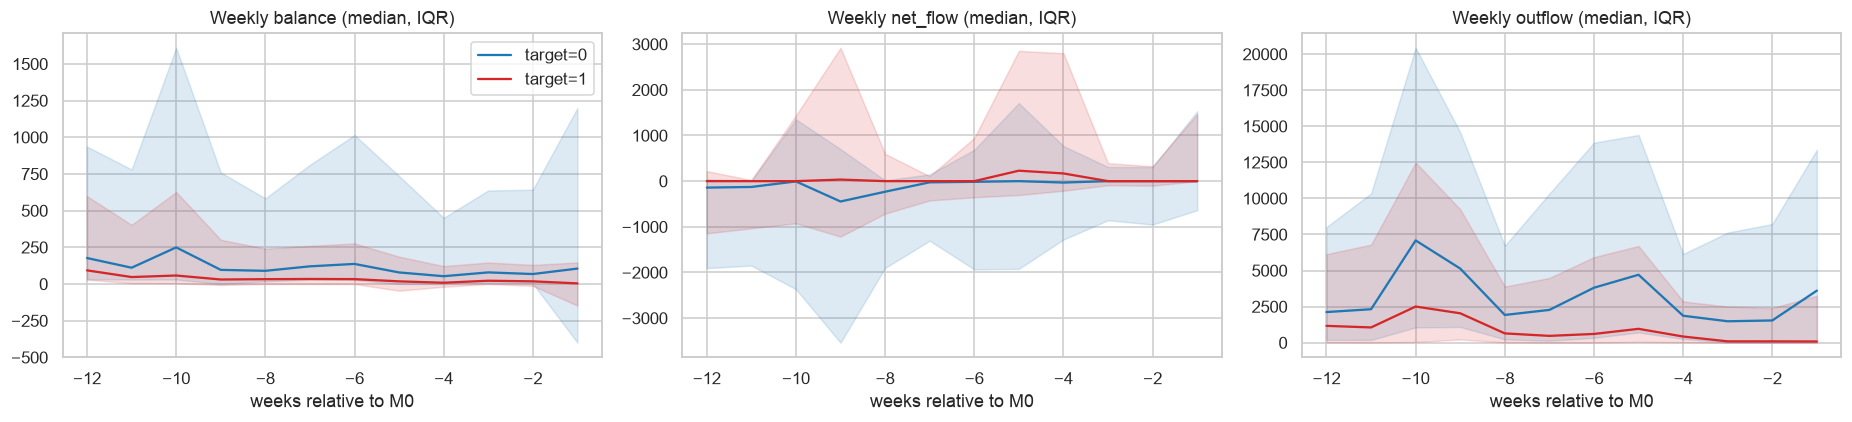

In [21]:
# Weekly trajectories before M0, by outcome: do future non-payers already look different over time?
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
xw = np.arange(N_WEEKS) - N_WEEKS
for ax, (name, M) in zip(axes, PANELS.items()):
    for t, colr in [(0, "tab:blue"), (1, "tab:red")]:
        sub = M[(y.values == t)]
        med, q1, q3 = sub.median(), sub.quantile(.25), sub.quantile(.75)
        ax.plot(xw, med.values, color=colr, label=f"target={t}")
        ax.fill_between(xw, q1.values, q3.values, color=colr, alpha=.15)
    ax.set_title(f"Weekly {name} (median, IQR)"); ax.set_xlabel("weeks relative to M0")
axes[0].legend()
plt.tight_layout(); plt.show()

,group,AUC,separation,p_value
feature,,,,
outflow_30d,recent,0.2976,0.4049,0.0000
outflow_14d,recent,0.3174,0.3652,0.0000
arrears_share_of_due,static,0.6825,0.3651,0.0000
weeks_net_neg,weekly,0.3327,0.3346,0.0000
bal_mean_30d,recent,0.3495,0.3010,0.0000
outflow_90d,flat,0.3496,0.3008,0.0000
outflow_to_inflow_90d,flat,0.3516,0.2968,0.0000
outflow_trend14,trend,0.3587,0.2826,0.0000
n_txn_14d,recent,0.3612,0.2776,0.0000


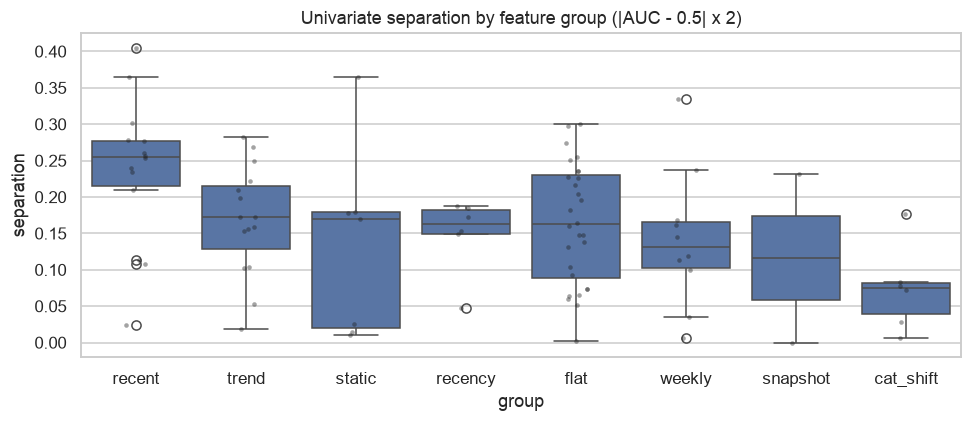

In [22]:
# Univariate separation (AUC) of every feature, tagged by group
rows = []
for c_ in X.columns:
    s = X[c_]
    a, b = s[y == 1].dropna(), s[y == 0].dropna()
    if len(a) > 20 and len(b) > 20 and s.nunique() > 1:
        u, p = stats.mannwhitneyu(a, b)
        auc = u / (len(a) * len(b))
        rows.append({"feature": c_, "group": col2grp[c_], "AUC": auc, "separation": abs(auc - 0.5) * 2, "p_value": p})
sep = pd.DataFrame(rows).set_index("feature").sort_values("separation", ascending=False)
display(sep.head(25))

order = sep.groupby("group")["separation"].median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=sep.reset_index(), x="group", y="separation", order=order, ax=ax)
sns.stripplot(data=sep.reset_index(), x="group", y="separation", order=order, color="k", alpha=.4, size=3, ax=ax)
ax.set_title("Univariate separation by feature group (|AUC - 0.5| x 2)")
plt.tight_layout(); plt.show()

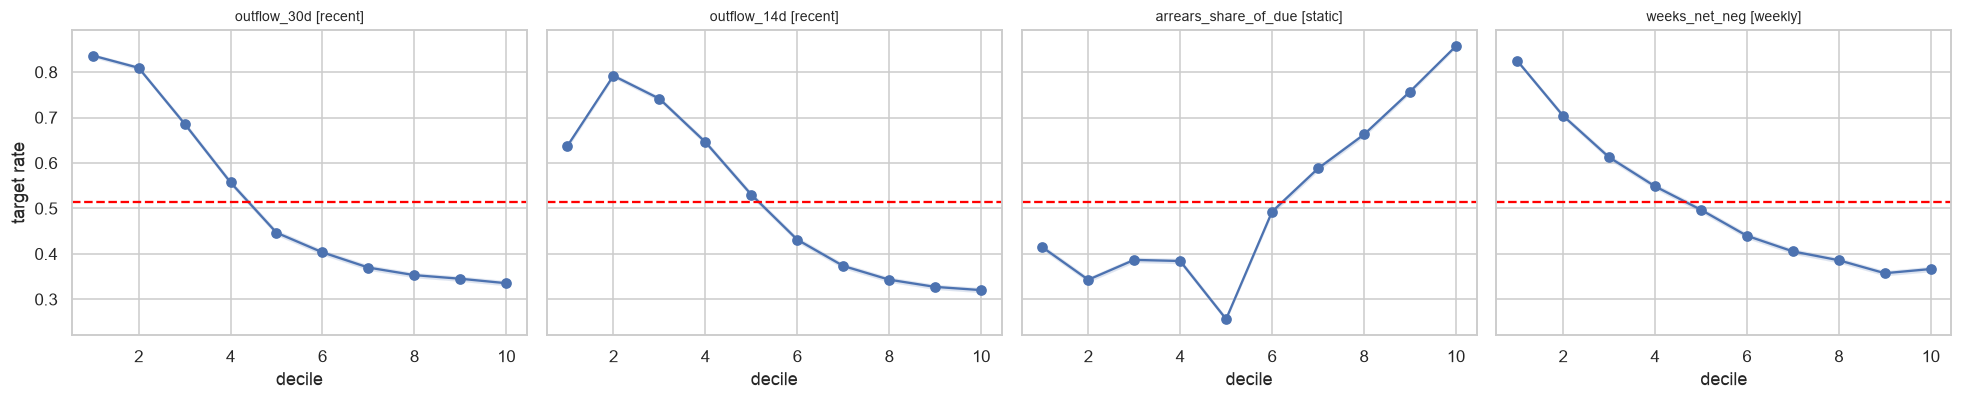

Decile edges of bal_at_m0: [-5.72571820e+05 -1.26891900e+04 -3.04936000e+03 -6.00000000e+00
  1.60000000e+00  3.14700000e+01  8.26600000e+01  3.03600000e+02
  9.09240000e+02  2.92819000e+03  2.21265467e+06]


,count,n_pos,rate,ci_lo,ci_hi,lift
zone,,,,,,
overdrawn,75718,44005,0.5812,0.5777,0.5847,1.1301
0-100,54443,30577,0.5616,0.5575,0.5658,1.0922
100-1000,48366,20777,0.4296,0.4252,0.4340,0.8354
>1000,47370,14479,0.3057,0.3015,0.3098,0.5944
exactly 0,21356,17311,0.8106,0.8053,0.8158,1.5763


In [23]:
# Target rate by decile for the strongest features (shows shape, incl. non-monotonic effects)
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8), sharey=True)
overall = y.mean()
for ax, c_ in zip(axes, sep.head(4).index):
    d = pd.DataFrame({"v": X[c_], "y": y}).dropna()
    d["decile"] = pd.qcut(d["v"].rank(method="first"), 10, labels=False) + 1
    g = d.groupby("decile")["y"].agg(["mean", "count", "sum"])
    lo, hi = proportion_confint(g["sum"], g["count"], method="wilson")
    ax.plot(g.index, g["mean"], marker="o"); ax.fill_between(g.index, lo, hi, alpha=.2)
    ax.axhline(overall, color="red", ls="--"); ax.set_title(f"{c_} [{col2grp[c_]}]", fontsize=9); ax.set_xlabel("decile")
axes[0].set_ylabel("target rate")
plt.tight_layout(); plt.show()

# Closing-balance shape: the notebook's first run showed a non-monotonic effect, so look at the edges and exact zeros
if "bal_at_m0" in X.columns:
    b_ = X["bal_at_m0"]
    print("Decile edges of bal_at_m0:", np.round(b_.quantile(np.linspace(0, 1, 11)).values, 2))
    zones = pd.cut(b_, [-np.inf, -1e-9, 1e-9, 100, 1000, np.inf], labels=["overdrawn", "exactly 0", "0-100", "100-1000", ">1000"])
    display(rate_table(pd.DataFrame({"zone": zones, TARGET: y}), "zone", min_n=1))

In [24]:
# Category-level risk: customers who spent in a category during the look-back window vs target rate
if HAS_MIX:
    has = txn_s[["cid", MIX_COL]].drop_duplicates().merge(cust[["cid", TARGET]], on="cid", how="left")
    rt = rate_table(has, MIX_COL, min_n=50)
    print(f"Overall target rate: {cust[TARGET].mean():.2%}")
    display(rt.sort_values("lift", ascending=False).head(15))
    display(rt.sort_values("lift").head(10))
    del has

Overall target rate: 51.42%


,count,n_pos,rate,ci_lo,ci_hi,lift
categoryname,,,,,,
Insurance Payout,329,231,0.7021,0.6506,0.7490,1.5015
UIF Received,14853,8818,0.5937,0.5858,0.6016,1.2696
Savings,21807,12237,0.5612,0.5546,0.5677,1.2000
Loan Payments,60922,32323,0.5306,0.5266,0.5345,1.1346
Credit Card Payments,184837,97696,0.5286,0.5263,0.5308,1.1303
Employee Refund,754,396,0.5252,0.4895,0.5606,1.1231
Loans,17338,9087,0.5241,0.5167,0.5315,1.1208
Uncategorised,242645,125577,0.5175,0.5155,0.5195,1.1067
Fees,243392,125393,0.5152,0.5132,0.5172,1.1017


,count,n_pos,rate,ci_lo,ci_hi,lift
categoryname,,,,,,
Traffic Fines,559,187,0.3345,0.2967,0.3747,0.7154
Other Communication,8135,2880,0.3540,0.3437,0.3645,0.7571
Municipal Bill,5086,1849,0.3635,0.3504,0.3769,0.7774
Bonus,1733,636,0.3670,0.3446,0.3900,0.7848
Medical Aid,3946,1454,0.3685,0.3536,0.3836,0.7880
Other Household,5989,2234,0.3730,0.3609,0.3853,0.7977
Books/Stationery,751,282,0.3755,0.3416,0.4107,0.8030
Pets,9134,3435,0.3761,0.3662,0.3861,0.8042
Gifts,10552,3976,0.3768,0.3676,0.3861,0.8058


## 10. Model comparison framework

**Design**
* **Primary evaluation: out-of-time holdout.** Train on earlier M0 months, test on later ones. Customers who appear in the test period are removed from training so no customer is in both. Optional embargo (`EMBARGO_DAYS`) removes training snapshots whose outcome window overlaps the test period.
* **Same models for every feature set:** a regularised logistic regression (C tuned by inner CV) for interpretability and a gradient-boosted tree for non-linear / interaction effects. Hyperparameters are fixed identically across sets so differences come from features, not tuning.
* **Metrics:** ROC-AUC, PR-AUC, KS, Brier, log-loss, top-decile capture/lift, and out-of-sample McFadden R-squared (explanatory power).
* **Uncertainty:** paired bootstrap on the test set (same resamples for all models).

In [25]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss, log_loss,
                             roc_curve, precision_recall_curve)
from sklearn.calibration import calibration_curve
from sklearn.model_selection import StratifiedGroupKFold, GroupShuffleSplit

SEED = 42
TEST_FRAC = 0.30        # share of (latest) M0 snapshots held out
EMBARGO_DAYS = 0        # e.g. 90 to drop training snapshots whose outcome window overlaps the test period
N_BOOT = 500            # bootstrap resamples
RUN_CV = True           # grouped K-fold robustness check
N_PLACEBO = 3           # time-shuffle repetitions
MODEL_KINDS = ["LR", "GB"]

ids = X.index.get_level_values(ID).to_numpy()
m0s = pd.Series(pd.to_datetime(X.index.get_level_values(M0)))

def make_model(kind):
    if kind == "LR":
        return Pipeline([
            ("imp", SimpleImputer(strategy="median")),
            ("slog", FunctionTransformer(slog_np)),
            ("sc", StandardScaler()),
            ("clf", LogisticRegressionCV(Cs=[1e-3, 1e-2, 1e-1, 1.0], cv=3, scoring="roc_auc",
                                         max_iter=3000, n_jobs=-1)),
        ])
    return HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=400,
                                          l2_regularization=1.0, early_stopping=True,
                                          validation_fraction=0.15, n_iter_no_change=20,
                                          random_state=SEED)

# ---- out-of-time split
split_type = "out-of-time"
ok = m0s.notna().all() and m0s.nunique() >= 4
if ok:
    cutoff = m0s.quantile(1 - TEST_FRAC)
    test_mask = (m0s > cutoff).to_numpy()
    train_mask = (m0s <= cutoff - pd.Timedelta(days=EMBARGO_DAYS)).to_numpy().copy()
    train_mask &= ~np.isin(ids, ids[test_mask])
    ok = test_mask.sum() >= 200 and y.values[test_mask].sum() >= 20 and train_mask.sum() >= 200
if not ok:
    split_type = "grouped random (fallback: too few M0 months or too small a test set)"
    gss = GroupShuffleSplit(n_splits=1, test_size=TEST_FRAC, random_state=SEED)
    tr_i, te_i = next(gss.split(X, y, groups=ids))
    train_mask = np.zeros(len(X), bool); train_mask[tr_i] = True
    test_mask = np.zeros(len(X), bool); test_mask[te_i] = True

Xtr, Xte = X[train_mask], X[test_mask]
ytr, yte = y.values[train_mask], y.values[test_mask]
print(f"Split type: {split_type}")
print(f"Train: {len(Xtr):,} rows, event rate {ytr.mean():.2%}, M0 {m0s[train_mask].min().date()} -> {m0s[train_mask].max().date()}")
print(f"Test : {len(Xte):,} rows, event rate {yte.mean():.2%}, M0 {m0s[test_mask].min().date()} -> {m0s[test_mask].max().date()}")
print(f"Max rows per customer in test: {pd.Series(ids[test_mask]).value_counts().max()} (1 means row bootstrap = customer bootstrap)")

Split type: out-of-time
Train: 138,626 rows, event rate 50.92%, M0 2025-09-30 -> 2026-01-31
Test : 44,114 rows, event rate 49.29%, M0 2026-02-28 -> 2026-02-28
Max rows per customer in test: 1 (1 means row bootstrap = customer bootstrap)


In [26]:
def ks_stat(y_, p_):
    fpr, tpr, _ = roc_curve(y_, p_)
    return float(np.max(tpr - fpr))

def capture_at(y_, p_, frac=0.10):
    k = max(1, int(len(p_) * frac))
    top = np.argsort(-p_)[:k]
    return float(y_[top].sum() / y_.sum())

def metrics(y_, p_, p0):
    p_ = np.clip(p_, 1e-6, 1 - 1e-6)
    ll0 = log_loss(y_, np.full(len(y_), p0))
    cap = capture_at(y_, p_)
    return {"AUC": roc_auc_score(y_, p_), "PR_AUC": average_precision_score(y_, p_), "KS": ks_stat(y_, p_),
            "Brier": brier_score_loss(y_, p_), "LogLoss": log_loss(y_, p_),
            "Top10%_capture": cap, "Top10%_lift": cap / 0.10,
            "OOS_McFadden_R2": 1 - log_loss(y_, p_) / ll0}

PRED, ROWS = {}, []
for sname, cs_ in SETS.items():
    for kind in MODEL_KINDS:
        m = make_model(kind).fit(Xtr[cs_], ytr)
        p = m.predict_proba(Xte[cs_])[:, 1]
        PRED[(sname, kind)] = p
        r = metrics(yte, p, ytr.mean()); r.update(set=sname, model=kind, n_features=len(cs_))
        ROWS.append(r)
        print(f"fitted {sname:22s} {kind}  AUC={r['AUC']:.4f}")
RESULTS = pd.DataFrame(ROWS).set_index(["model", "set"])

fitted A_static               LR  AUC=0.7269
fitted A_static               GB  AUC=0.7618
fitted B_static+snapshot      LR  AUC=0.7303
fitted B_static+snapshot      GB  AUC=0.7921
fitted C_static+snap+flat     LR  AUC=0.7562
fitted C_static+snap+flat     GB  AUC=0.8094
fitted D_time_aware_only      LR  AUC=0.7630
fitted D_time_aware_only      GB  AUC=0.8000
fitted E_full                 LR  AUC=0.8072
fitted E_full                 GB  AUC=0.8324


## 11. Results: static vs time-aware

,,AUC,PR_AUC,KS,Brier,LogLoss,Top10%_capture,Top10%_lift,OOS_McFadden_R2,n_features
model,set,,,,,,,,,
LR,A_static,0.7269,0.7315,0.3595,0.2119,0.6164,0.1791,1.7910,0.1113,7
GB,A_static,0.7618,0.7634,0.3950,0.2008,0.5878,0.1818,1.8181,0.1525,7
LR,B_static+snapshot,0.7303,0.7353,0.3653,0.2109,0.6143,0.1797,1.7970,0.1143,9
GB,B_static+snapshot,0.7921,0.7988,0.4444,0.1875,0.5568,0.1889,1.8894,0.1973,9
LR,C_static+snap+flat,0.7562,0.7646,0.3837,0.2016,0.5924,0.1850,1.8503,0.1460,37
GB,C_static+snap+flat,0.8094,0.8155,0.4680,0.1797,0.5366,0.1920,1.9202,0.2264,37
LR,D_time_aware_only,0.7630,0.7737,0.4170,0.1957,0.5771,0.1845,1.8448,0.1680,51
GB,D_time_aware_only,0.8000,0.8117,0.4630,0.1806,0.5386,0.1920,1.9198,0.2235,51
LR,E_full,0.8072,0.8176,0.4818,0.1782,0.5379,0.1915,1.9147,0.2245,88


,,AUC,lo,hi
model,set,,,
LR,A_static,0.7269,0.7222,0.7314
GB,A_static,0.7618,0.7574,0.7661
LR,B_static+snapshot,0.7303,0.7258,0.7346
GB,B_static+snapshot,0.7921,0.7880,0.7960
LR,C_static+snap+flat,0.7562,0.7519,0.7603
GB,C_static+snap+flat,0.8094,0.8054,0.8133
LR,D_time_aware_only,0.7630,0.7585,0.7673
GB,D_time_aware_only,0.8000,0.7958,0.8041
LR,E_full,0.8072,0.8029,0.8111


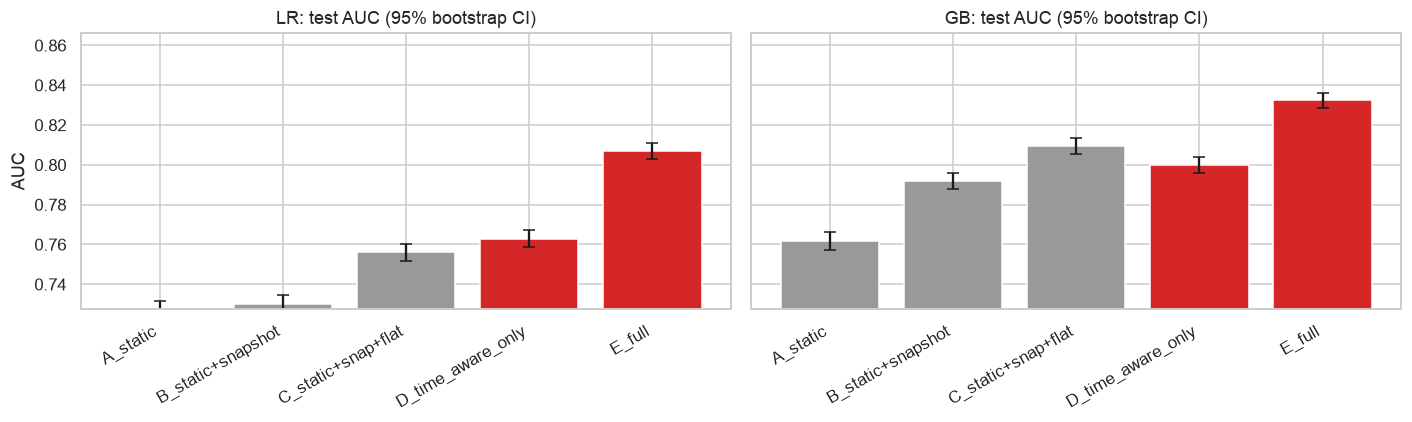

In [27]:
display(RESULTS.round(4))

# AUC bootstrap CIs (shared resamples => paired comparisons)
keys = list(PRED.keys())
rng = np.random.default_rng(SEED)
n = len(yte)
BOOT = np.full((N_BOOT, len(keys)), np.nan)
for b in range(N_BOOT):
    i = rng.integers(0, n, n)
    yy = yte[i]
    if yy.min() == yy.max():
        continue
    for j, k in enumerate(keys):
        BOOT[b, j] = roc_auc_score(yy, PRED[k][i])
kidx = {k: j for j, k in enumerate(keys)}
ci = pd.DataFrame({"AUC": [RESULTS.loc[(k[1], k[0]), "AUC"] for k in keys],
                   "lo": np.nanpercentile(BOOT, 2.5, axis=0), "hi": np.nanpercentile(BOOT, 97.5, axis=0)},
                  index=pd.MultiIndex.from_tuples([(k[1], k[0]) for k in keys], names=["model", "set"]))
display(ci.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, kind in zip(axes, MODEL_KINDS):
    sub = ci.loc[kind]
    ax.bar(range(len(sub)), sub["AUC"], yerr=[sub["AUC"] - sub["lo"], sub["hi"] - sub["AUC"]], capsize=4,
           color=["#999", "#999", "#999", "#d62728", "#d62728"][:len(sub)])
    ax.set_xticks(range(len(sub))); ax.set_xticklabels(sub.index, rotation=30, ha="right")
    ax.set_title(f"{kind}: test AUC (95% bootstrap CI)")
    ax.set_ylim(max(0.45, sub["lo"].min() - 0.03), min(1.0, sub["hi"].max() + 0.03))
axes[0].set_ylabel("AUC")
plt.tight_layout(); plt.show()

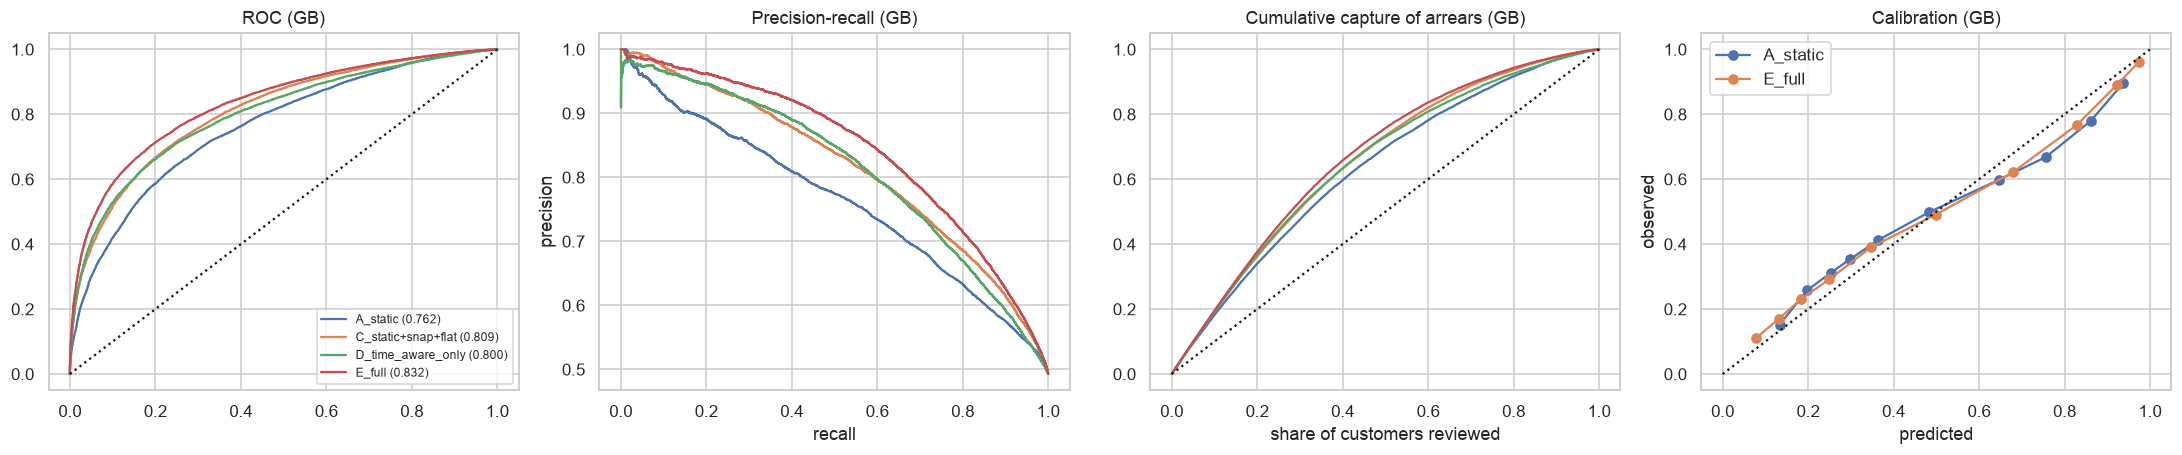

In [28]:
# ROC / PR curves, lift and calibration (gradient boosting)
show = ["A_static", "C_static+snap+flat", "D_time_aware_only", "E_full"]
fig, ax = plt.subplots(1, 4, figsize=(20, 4.3))
for s_ in show:
    p = PRED[(s_, "GB")]
    fpr, tpr, _ = roc_curve(yte, p); ax[0].plot(fpr, tpr, label=f"{s_} ({roc_auc_score(yte, p):.3f})")
    pr, rc, _ = precision_recall_curve(yte, p); ax[1].plot(rc, pr, label=s_)
    order_ = np.argsort(-p); cum = np.cumsum(yte[order_]) / yte.sum()
    ax[2].plot(np.arange(1, len(p) + 1) / len(p), cum, label=s_)
for s_ in ["A_static", "E_full"]:
    fp, mp = calibration_curve(yte, PRED[(s_, "GB")], n_bins=10, strategy="quantile")
    ax[3].plot(mp, fp, marker="o", label=s_)
ax[0].plot([0, 1], [0, 1], "k:"); ax[0].set_title("ROC (GB)"); ax[0].legend(fontsize=8)
ax[1].set_title("Precision-recall (GB)"); ax[1].set_xlabel("recall"); ax[1].set_ylabel("precision")
ax[2].plot([0, 1], [0, 1], "k:"); ax[2].set_title("Cumulative capture of arrears (GB)"); ax[2].set_xlabel("share of customers reviewed")
ax[3].plot([0, 1], [0, 1], "k:"); ax[3].set_title("Calibration (GB)"); ax[3].set_xlabel("predicted"); ax[3].set_ylabel("observed"); ax[3].legend()
plt.tight_layout(); plt.show()

## 12. Statistical significance and explanatory power

In [29]:
# Paired bootstrap of AUC differences on the test set
COMPARE = [
    ("D_time_aware_only", "A_static",           "H1: time-aware alone vs static alone"),
    ("E_full",            "C_static+snap+flat", "H2: add time-aware on top of best non-temporal baseline"),
    ("E_full",            "A_static",           "Full vs static"),
    ("C_static+snap+flat", "A_static",          "Non-temporal transaction info vs static"),
    ("D_time_aware_only", "C_static+snap+flat", "Time-aware alone vs non-temporal baseline"),
]
RES_DIFF, rows = {}, []
for kind in MODEL_KINDS:
    for new, ref, label in COMPARE:
        d = BOOT[:, kidx[(new, kind)]] - BOOT[:, kidx[(ref, kind)]]
        d = d[~np.isnan(d)]
        mean = RESULTS.loc[(kind, new), "AUC"] - RESULTS.loc[(kind, ref), "AUC"]
        lo, hi = np.percentile(d, [2.5, 97.5])
        p = min(1.0, 2 * min((d <= 0).mean(), (d >= 0).mean()))
        RES_DIFF[(kind, new, ref)] = (mean, lo, hi, p)
        rows.append({"model": kind, "comparison": label, "new": new, "ref": ref,
                     "dAUC": mean, "CI_lo": lo, "CI_hi": hi, "p_boot": p,
                     "dTop10_capture": RESULTS.loc[(kind, new), "Top10%_capture"] - RESULTS.loc[(kind, ref), "Top10%_capture"],
                     "dOOS_R2": RESULTS.loc[(kind, new), "OOS_McFadden_R2"] - RESULTS.loc[(kind, ref), "OOS_McFadden_R2"]})
display(pd.DataFrame(rows).round(4))

,model,comparison,new,ref,dAUC,CI_lo,CI_hi,p_boot,dTop10_capture,dOOS_R2
0,LR,H1: time-aware alone vs static alone,D_time_aware_only,A_static,0.0361,0.0306,0.0415,0.0000,0.0054,0.0567
1,LR,H2: add time-aware on top of best non-temporal...,E_full,C_static+snap+flat,0.0510,0.0484,0.0535,0.0000,0.0064,0.0786
2,LR,Full vs static,E_full,A_static,0.0803,0.0769,0.0840,0.0000,0.0124,0.1133
3,LR,Non-temporal transaction info vs static,C_static+snap+flat,A_static,0.0294,0.0268,0.0321,0.0000,0.0059,0.0347
4,LR,Time-aware alone vs non-temporal baseline,D_time_aware_only,C_static+snap+flat,0.0067,0.0021,0.0113,0.0040,-0.0006,0.0220
5,GB,H1: time-aware alone vs static alone,D_time_aware_only,A_static,0.0382,0.0331,0.0435,0.0000,0.0102,0.0710
6,GB,H2: add time-aware on top of best non-temporal...,E_full,C_static+snap+flat,0.0229,0.0210,0.0250,0.0000,0.0031,0.0446
7,GB,Full vs static,E_full,A_static,0.0706,0.0676,0.0737,0.0000,0.0133,0.1185
8,GB,Non-temporal transaction info vs static,C_static+snap+flat,A_static,0.0476,0.0450,0.0502,0.0000,0.0102,0.0739
9,GB,Time-aware alone vs non-temporal baseline,D_time_aware_only,C_static+snap+flat,-0.0095,-0.0132,-0.0055,0.0000,-0.0000,-0.0029


In [30]:
# Nested likelihood-ratio tests (in-sample, training data, near-unpenalised logistic regression).
# A subset of B subset of C subset of E, so all comparisons are nested.
from scipy.stats import chi2

def fit_ll(cs_):
    pp = Pipeline([("imp", SimpleImputer(strategy="median")), ("slog", FunctionTransformer(slog_np)), ("sc", StandardScaler())])
    Z = pp.fit_transform(Xtr[cs_])
    m = LogisticRegression(C=1e6, max_iter=5000).fit(Z, ytr)
    ll = -log_loss(ytr, np.clip(m.predict_proba(Z)[:, 1], 1e-9, 1 - 1e-9), normalize=False)
    return ll, Z.shape[1]

LL = {k: fit_ll(v) for k, v in SETS.items() if k != "D_time_aware_only"}
ntr = len(ytr)
lr_rows = []
for small, big in [("A_static", "C_static+snap+flat"), ("C_static+snap+flat", "E_full"), ("A_static", "E_full")]:
    (ll_s, k_s), (ll_b, k_b) = LL[small], LL[big]
    stat = max(0.0, 2 * (ll_b - ll_s)); dfree = k_b - k_s
    lr_rows.append({"reduced": small, "full": big, "LR_stat": stat, "df": dfree, "p_value": chi2.sf(stat, dfree) if dfree > 0 else np.nan,
                    "dAIC": (2 * k_b - 2 * ll_b) - (2 * k_s - 2 * ll_s),
                    "dBIC": (k_b * np.log(ntr) - 2 * ll_b) - (k_s * np.log(ntr) - 2 * ll_s)})
lr_tbl = pd.DataFrame(lr_rows)
display(lr_tbl)
print("Negative dAIC / dBIC favours the fuller model. With large n the LR test is almost always significant, so rely on effect sizes (out-of-sample AUC / R2) and BIC.")

# Out-of-sample McFadden R2 = share of null log-loss explained on unseen later-period data
display(RESULTS["OOS_McFadden_R2"].unstack("model").round(4))

,reduced,full,LR_stat,df,p_value,dAIC,dBIC
0,A_static,C_static+snap+flat,"13,275.2982",30,0.0000,"-13,215.2982","-12,920.1121"
1,C_static+snap+flat,E_full,"16,843.2027",51,0.0000,"-16,741.2027","-16,239.3865"
2,A_static,E_full,"30,118.5009",81,0.0000,"-29,956.5009","-29,159.4986"


Negative dAIC / dBIC favours the fuller model. With large n the LR test is almost always significant, so rely on effect sizes (out-of-sample AUC / R2) and BIC.


model,GB,LR
set,,
A_static,0.1525,0.1113
B_static+snapshot,0.1973,0.1143
C_static+snap+flat,0.2264,0.1460
D_time_aware_only,0.2235,0.1680
E_full,0.2710,0.2245


## 13. Ablation: which temporal features matter

,n_features,dAUC_if_removed_from_full,rm_lo,rm_hi,dAUC_if_added_to_baseline,add_lo,add_hi
group,,,,,,,
recent,14,-0.0062,-0.0070,-0.0052,0.0235,0.0218,0.0253
trend,15,-0.0004,-0.0010,0.0001,0.0191,0.0174,0.0209
weekly,10,-0.0000,-0.0004,0.0003,0.0056,0.0044,0.0070
recency,6,0.0000,-0.0003,0.0004,0.0025,0.0017,0.0032
cat_shift,6,0.0016,0.0008,0.0025,0.0017,0.0004,0.0032


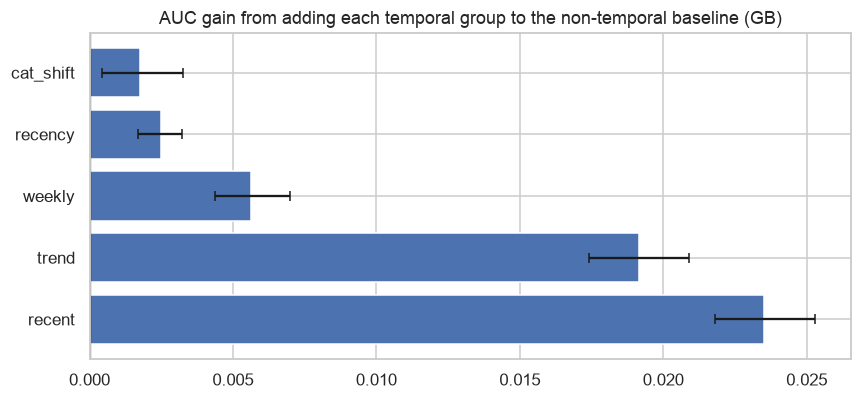

In [31]:
def paired_delta(y_, p_new, p_ref, n_boot=N_BOOT, seed=SEED):
    r = np.random.default_rng(seed); n_ = len(y_); d = []
    for _ in range(n_boot):
        i = r.integers(0, n_, n_)
        if y_[i].min() == y_[i].max():
            continue
        d.append(roc_auc_score(y_[i], p_new[i]) - roc_auc_score(y_[i], p_ref[i]))
    d = np.array(d)
    return roc_auc_score(y_, p_new) - roc_auc_score(y_, p_ref), *np.percentile(d, [2.5, 97.5])

def gb_pred(cs_):
    m = make_model("GB").fit(Xtr[cs_], ytr)
    return m.predict_proba(Xte[cs_])[:, 1]

pE = PRED[("E_full", "GB")]; pC = PRED[("C_static+snap+flat", "GB")]
rows = []
for g_ in TIME_GROUPS:
    if not GROUPS[g_]:
        continue
    # leave one temporal group out of the full model
    cs_drop = [c_ for c_ in SETS["E_full"] if col2grp[c_] != g_]
    d1 = paired_delta(yte, gb_pred(cs_drop), pE)
    # add one temporal group to the non-temporal baseline
    d2 = paired_delta(yte, gb_pred(SETS["C_static+snap+flat"] + GROUPS[g_]), pC)
    rows.append({"group": g_, "n_features": len(GROUPS[g_]),
                 "dAUC_if_removed_from_full": d1[0], "rm_lo": d1[1], "rm_hi": d1[2],
                 "dAUC_if_added_to_baseline": d2[0], "add_lo": d2[1], "add_hi": d2[2]})
abl = pd.DataFrame(rows).set_index("group")
display(abl.round(4))

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(abl.index, abl["dAUC_if_added_to_baseline"],
        xerr=[abl["dAUC_if_added_to_baseline"] - abl["add_lo"], abl["add_hi"] - abl["dAUC_if_added_to_baseline"]], capsize=3)
ax.axvline(0, color="k", lw=.8); ax.set_title("AUC gain from adding each temporal group to the non-temporal baseline (GB)")
plt.tight_layout(); plt.show()

,type,AUC_drop_mean,AUC_drop_sd
group,,,
static,static/flat,0.1107,0.0012
recent,time-aware,0.0492,0.0005
flat,static/flat,0.0257,0.0004
trend,time-aware,0.0127,0.0006
cat_shift,time-aware,0.0058,0.0003
snapshot,static/flat,0.0042,0.0003
recency,time-aware,0.0025,0.0004
weekly,time-aware,0.0014,0.0002


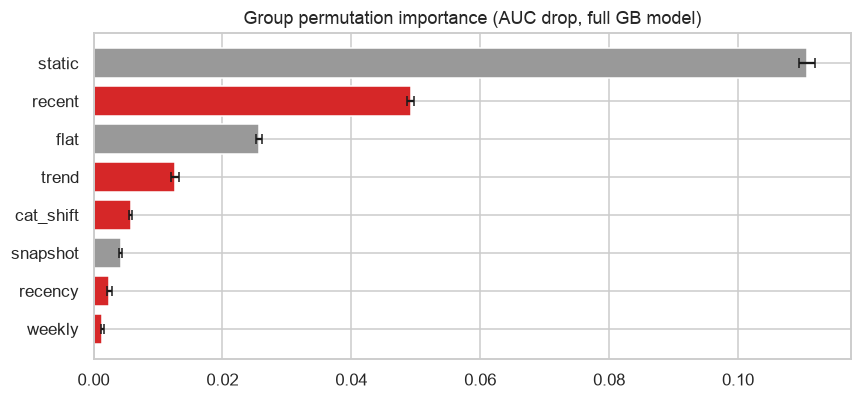

In [32]:
# Grouped permutation importance on the test set for the full GB model (permute a whole group jointly)
mE = make_model("GB").fit(Xtr[SETS["E_full"]], ytr)
base_auc = roc_auc_score(yte, mE.predict_proba(Xte[SETS["E_full"]])[:, 1])
rp = np.random.default_rng(SEED)
imp = []
for g_, cs_ in GROUPS.items():
    if not cs_:
        continue
    drops = []
    for _ in range(5):
        Xp = Xte[SETS["E_full"]].copy()
        perm = rp.permutation(len(Xp))
        Xp[cs_] = Xp[cs_].to_numpy()[perm]
        drops.append(base_auc - roc_auc_score(yte, mE.predict_proba(Xp)[:, 1]))
    imp.append({"group": g_, "type": "time-aware" if g_ in TIME_GROUPS else "static/flat",
                "AUC_drop_mean": np.mean(drops), "AUC_drop_sd": np.std(drops)})
imp = pd.DataFrame(imp).sort_values("AUC_drop_mean", ascending=False).set_index("group")
display(imp.round(4))
fig, ax = plt.subplots(figsize=(8, 3.8))
colors = ["#d62728" if t == "time-aware" else "#999" for t in imp["type"]]
ax.barh(imp.index[::-1], imp["AUC_drop_mean"][::-1], xerr=imp["AUC_drop_sd"][::-1], color=colors[::-1], capsize=3)
ax.set_title("Group permutation importance (AUC drop, full GB model)")
plt.tight_layout(); plt.show()

,feature,AUC_drop,sd,group
3,arrears_share_of_due,0.0548,0.0007,static
1,m0_total_due_with_arrears,0.0234,0.0006,static
41,bal_min_14d,0.0160,0.0004,recent
46,outflow_30d,0.0087,0.0003,recent
6,"method_Early Debit Order, linked to clients pa...",0.0084,0.0003,static
13,bal_min_90d,0.0077,0.0004,flat
7,bal_at_m0,0.0044,0.0001,snapshot
2,due_count,0.0042,0.0002,static
86,shift_other_loans_and_accounts,0.0041,0.0004,cat_shift
47,bal_mean_30d,0.0028,0.0002,recent


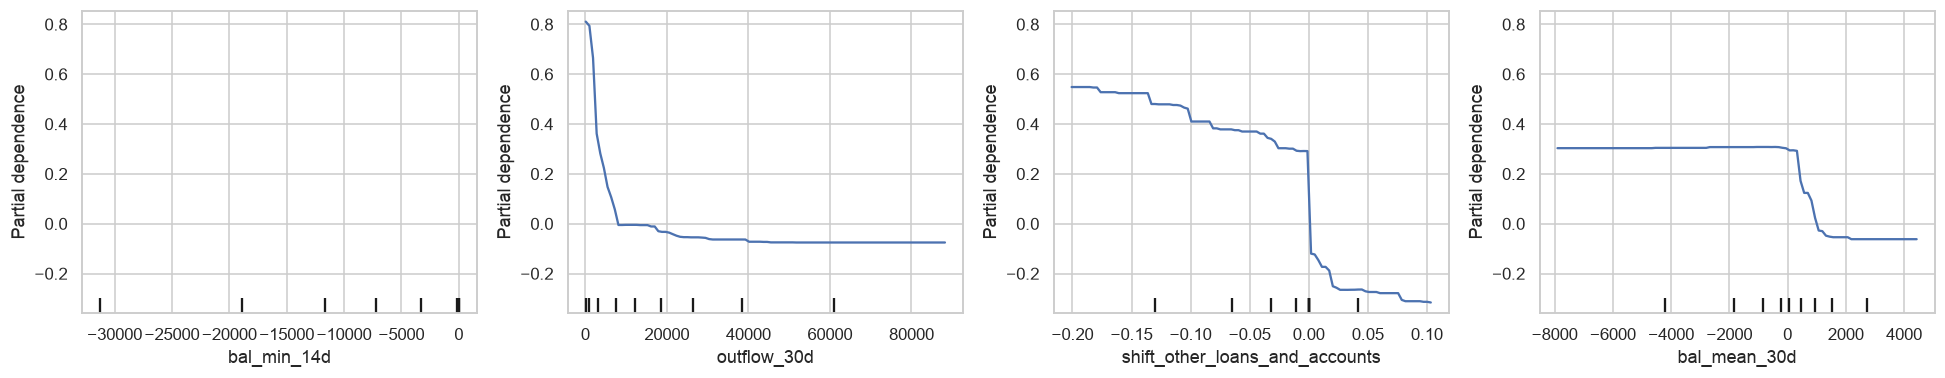

In [33]:
# Top individual features by permutation importance (full GB), with their group
from sklearn.inspection import permutation_importance
pi = permutation_importance(mE, Xte[SETS["E_full"]], yte, scoring="roc_auc", n_repeats=5, random_state=SEED, n_jobs=-1)
pif = (pd.DataFrame({"feature": SETS["E_full"], "AUC_drop": pi.importances_mean, "sd": pi.importances_std})
         .assign(group=lambda d: d["feature"].map(col2grp)).sort_values("AUC_drop", ascending=False))
display(pif.head(20).round(4))

# Partial dependence of the top temporal features (shape of the effect)
from sklearn.inspection import PartialDependenceDisplay
top_t = [f for f in pif["feature"] if col2grp[f] in TIME_GROUPS][:4]
fig, ax = plt.subplots(1, len(top_t), figsize=(4.5 * len(top_t), 3.6))
ax = np.atleast_1d(ax)
PartialDependenceDisplay.from_estimator(mE, Xte[SETS["E_full"]], top_t, ax=ax, kind="average")
plt.tight_layout(); plt.show()

## 14. Placebo test: does *timing* matter?

For each customer we randomly reassign the **timing** of their transactions within the look-back window,
keeping amounts, balances and categories attached to the same rows. Total activity and its composition are unchanged,
but trends, slopes, recency and gaps are destroyed. We rebuild the time-aware features from the shuffled data and
refit the full model. If time-aware structure drives the gain, the placebo AUC should fall back toward the
non-temporal baseline `C`. The time-agnostic `flat` and `static` features are left untouched.

In [34]:
PLACEBO = {"GB": [], "LR": []}
PLACEBO_PRED = None
time_cols = cols(*TIME_GROUPS)
for rep in range(N_PLACEBO):
    t_sh = to_base(run_batches(parts=("time",), shuffle_seed=SEED + rep, verbose=False)["time"])
    Xp = X.copy()
    Xp[time_cols] = t_sh[time_cols].replace([np.inf, -np.inf], np.nan)
    Xp_tr, Xp_te = Xp[train_mask], Xp[test_mask]
    mg = make_model("GB").fit(Xp_tr[SETS["E_full"]], ytr)
    pg = mg.predict_proba(Xp_te[SETS["E_full"]])[:, 1]
    PLACEBO["GB"].append(roc_auc_score(yte, pg))
    if rep == 0:
        PLACEBO_PRED = pg
        ml = make_model("LR").fit(Xp_tr[SETS["E_full"]], ytr)
        PLACEBO["LR"].append(roc_auc_score(yte, ml.predict_proba(Xp_te[SETS["E_full"]])[:, 1]))
    del Xp, Xp_tr, Xp_te, t_sh
    print(f"placebo rep {rep}: GB AUC = {PLACEBO['GB'][-1]:.4f}")

tbl = pd.DataFrame({
    "A_static (GB)": [RESULTS.loc[("GB", "A_static"), "AUC"]],
    "C_non-temporal (GB)": [RESULTS.loc[("GB", "C_static+snap+flat"), "AUC"]],
    "E_full real timing (GB)": [RESULTS.loc[("GB", "E_full"), "AUC"]],
    "E_full shuffled timing (GB, mean)": [np.mean(PLACEBO["GB"])],
}).T.rename(columns={0: "test AUC"})
display(tbl.round(4))

PLACEBO_DIFF = paired_delta(yte, pE, PLACEBO_PRED)
print(f"Real minus shuffled timing (GB, rep 0): dAUC = {PLACEBO_DIFF[0]:.4f}  95% CI [{PLACEBO_DIFF[1]:.4f}, {PLACEBO_DIFF[2]:.4f}]")
PLACEBO_VS_C = paired_delta(yte, PLACEBO_PRED, pC)
print(f"Shuffled-timing full vs non-temporal baseline C: dAUC = {PLACEBO_VS_C[0]:.4f}  95% CI [{PLACEBO_VS_C[1]:.4f}, {PLACEBO_VS_C[2]:.4f}]")
print("(If this is near zero, nothing beyond the non-temporal baseline survives once timing is destroyed.)")

placebo rep 0: GB AUC = 0.8163
placebo rep 1: GB AUC = 0.8169
placebo rep 2: GB AUC = 0.8171


,test AUC
A_static (GB),0.7618
C_non-temporal (GB),0.8094
E_full real timing (GB),0.8324
"E_full shuffled timing (GB, mean)",0.8168


Real minus shuffled timing (GB, rep 0): dAUC = 0.0160  95% CI [0.0145, 0.0178]
Shuffled-timing full vs non-temporal baseline C: dAUC = 0.0069  95% CI [0.0056, 0.0083]
(If this is near zero, nothing beyond the non-temporal baseline survives once timing is destroyed.)


## 15. Robustness

,n,event_rate,A_static,C_static+snap+flat,E_full
M0 month,,,,,
2026-02,44114,0.4929,0.7618,0.8094,0.8324


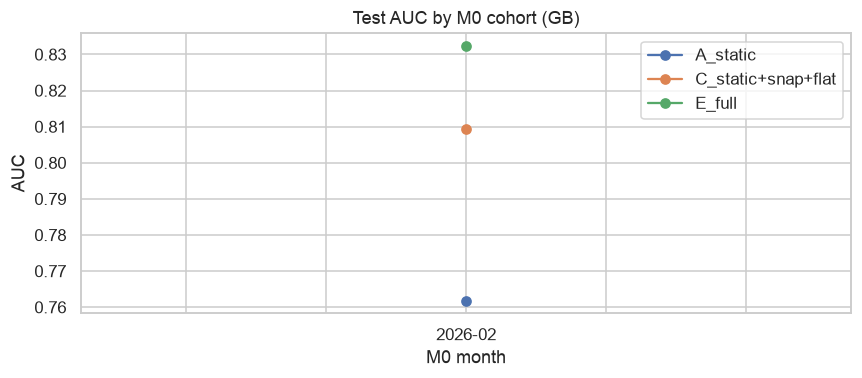

In [35]:
# (a) Stability across later M0 cohorts within the test period (GB)
tm = m0s[test_mask].dt.to_period("M").astype(str).to_numpy()
rows = []
for mth in sorted(set(tm)):
    sel = tm == mth
    if yte[sel].sum() >= 10 and (1 - yte[sel]).sum() >= 10:
        rows.append({"M0 month": mth, "n": int(sel.sum()), "event_rate": yte[sel].mean(),
                     **{s_: roc_auc_score(yte[sel], PRED[(s_, "GB")][sel]) for s_ in ["A_static", "C_static+snap+flat", "E_full"]}})
if rows:
    coh = pd.DataFrame(rows).set_index("M0 month")
    display(coh.round(4))
    ax = coh[["A_static", "C_static+snap+flat", "E_full"]].plot(marker="o", figsize=(8, 3.6), title="Test AUC by M0 cohort (GB)")
    ax.set_ylabel("AUC"); plt.tight_layout(); plt.show()
else:
    print("Not enough events per test month for a cohort breakdown.")

In [36]:
# (b) Grouped K-fold CV on all data (random, not time-ordered): checks the result is not an artefact of one split. GB only.
CV_TBL = None
if RUN_CV:
    sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    cv_rows = []
    for f, (tr_i, te_i) in enumerate(sgkf.split(X, y, groups=ids)):
        rec_ = {"fold": f}
        for s_ in ["A_static", "C_static+snap+flat", "D_time_aware_only", "E_full"]:
            m = make_model("GB").fit(X.iloc[tr_i][SETS[s_]], y.values[tr_i])
            rec_[s_] = roc_auc_score(y.values[te_i], m.predict_proba(X.iloc[te_i][SETS[s_]])[:, 1])
        cv_rows.append(rec_)
    CV_TBL = pd.DataFrame(cv_rows).set_index("fold")
    display(CV_TBL.round(4))
    for new, ref in [("D_time_aware_only", "A_static"), ("E_full", "C_static+snap+flat")]:
        d = CV_TBL[new] - CV_TBL[ref]
        t, p = stats.ttest_1samp(d, 0.0)
        print(f"{new} - {ref}: mean dAUC = {d.mean():.4f} (sd {d.std():.4f}), folds positive = {(d > 0).sum()}/{len(d)}, paired t p = {p:.4f}")

,A_static,C_static+snap+flat,D_time_aware_only,E_full
fold,,,,
0,0.7606,0.8156,0.8121,0.8439
1,0.7600,0.8119,0.8095,0.8409
2,0.7582,0.8168,0.8126,0.8437
3,0.7607,0.8159,0.8086,0.8421
4,0.7568,0.8118,0.8066,0.8381


D_time_aware_only - A_static: mean dAUC = 0.0506 (sd 0.0025), folds positive = 5/5, paired t p = 0.0000
E_full - C_static+snap+flat: mean dAUC = 0.0273 (sd 0.0012), folds positive = 5/5, paired t p = 0.0000


## 16. Verdict and outputs

In [37]:
def verdict_line(label, mean, lo, hi):
    status = "SUPPORTED" if lo > 0 else ("NOT SUPPORTED" if hi < 0 else "INCONCLUSIVE (CI includes 0)")
    return f"{label:70s} dAUC={mean:+.4f}  95% CI [{lo:+.4f}, {hi:+.4f}]  -> {status}"

print("=" * 120)
print("TIME-AWARE vs STATIC: SUMMARY (out-of-time test set)")
print("=" * 120)
flags = []
for kind in MODEL_KINDS:
    h1 = RES_DIFF[(kind, "D_time_aware_only", "A_static")]
    h2 = RES_DIFF[(kind, "E_full", "C_static+snap+flat")]
    print(verdict_line(f"[{kind}] H1 time-aware alone > static alone", *h1[:3]))
    print(verdict_line(f"[{kind}] H2 full > non-temporal baseline (static+snapshot+flat)", *h2[:3]))
    flags += [h1[1] > 0, h2[1] > 0]
print(verdict_line("[GB]  H3 real timing > shuffled timing (placebo)", *PLACEBO_DIFF))
flags.append(PLACEBO_DIFF[1] > 0)

fp = sum(flags)
print("-" * 120)
if fp == len(flags):
    print("OVERALL: strong support. Time-aware features beat static attributes, add value beyond non-temporal aggregates, and the gain disappears when timing is shuffled.")
elif fp >= len(flags) // 2:
    print("OVERALL: partial support. Review which hypotheses were inconclusive above (sample size, model class, or weak temporal signal).")
else:
    print("OVERALL: little support in this dataset. Static or flat features capture most of the signal; revisit window lengths and feature design.")
print("Caveats: single out-of-time split (see CV for stability); bootstrap treats test rows as independent; "
      "ensure the 'static' set contains every point-in-time attribute you consider fair; results describe prediction, not causation.")

TIME-AWARE vs STATIC: SUMMARY (out-of-time test set)
[LR] H1 time-aware alone > static alone                                dAUC=+0.0361  95% CI [+0.0306, +0.0415]  -> SUPPORTED
[LR] H2 full > non-temporal baseline (static+snapshot+flat)            dAUC=+0.0510  95% CI [+0.0484, +0.0535]  -> SUPPORTED
[GB] H1 time-aware alone > static alone                                dAUC=+0.0382  95% CI [+0.0331, +0.0435]  -> SUPPORTED
[GB] H2 full > non-temporal baseline (static+snapshot+flat)            dAUC=+0.0229  95% CI [+0.0210, +0.0250]  -> SUPPORTED
[GB]  H3 real timing > shuffled timing (placebo)                       dAUC=+0.0160  95% CI [+0.0145, +0.0178]  -> SUPPORTED
------------------------------------------------------------------------------------------------------------------------
OVERALL: strong support. Time-aware features beat static attributes, add value beyond non-temporal aggregates, and the gain disappears when timing is shuffled.
Caveats: single out-of-time split (see CV

In [38]:
# Save outputs
out = X.assign(**{TARGET: y}).reset_index()
out["split"] = np.where(train_mask, "train", np.where(test_mask, "test", "unused"))
out.to_parquet(OUTPUT_PATH, index=False)
RESULTS.reset_index().to_csv("model_comparison_results.csv", index=False)
pd.Series(col2grp, name="group").rename_axis("feature").reset_index().to_csv("feature_groups.csv", index=False)
print(f"Saved {OUTPUT_PATH} ({out.shape[0]:,} x {out.shape[1]}), model_comparison_results.csv, feature_groups.csv")

Saved customer_features.parquet (247,254 x 92), model_comparison_results.csv, feature_groups.csv


### How to read and extend this
* **If H1-H3 are supported:** the temporal structure carries real signal. Use the group-importance and partial-dependence outputs to describe *which* dynamics matter (for example, declining weekly balance slope, widening inflow gaps), and take the `E_full` feature table (`customer_features.parquet`) into the SOM with the target held out.
* **If H2 holds but H3 does not:** the gain comes from richer data rather than timing. Check `flat` window choices.
* **Fairness of the "static" baseline:** add any other point-in-time attributes you hold (tenure, product, income band) to the `static` group before concluding.
* **Stronger evidence:** repeat with several different cut-off dates (rolling out-of-time), set `EMBARGO_DAYS = 90`, and add survival or discrete-time hazard models for time-to-arrears.